# Optimización de hiperparámetros para predecir la popularidad de canciones de Spotify
## Random Search, Grid Search y validación cruzada hasta cumplir los criterios de éxito

| | |
|---|---|
| **Asignatura** | MLY1101 Machine Learning |
| **Evaluación** | Parcial Nro. 3: presentación y defensa técnica del proyecto |
| **Equipo** | Grupo 5: Cristian Romero y Rolando Paredes |
| **Caso** | C: inteligencia musical y predicción de popularidad de canciones (Spotify Tracks) |
| **Metodología** | CRISP-DM, fase 4 (modelado con ajuste de hiperparámetros) y fase 5 (evaluación) |
| **Entrada** | Solo lo que exporta la EV2 en `data/processed/ev2/` |
| **Informe** | `README.md` resume este notebook; aquí está el respaldo de cada cifra |

### Índice

1. Objetivo, criterios de éxito e hipótesis
2. Entrada: lo que exporta la EV2
3. Los tres modelos y sus hiperparámetros
4. Punto de partida: hiperparámetros por defecto
5. Optimización: primero Random Search y después Grid Search
6. Evaluación en prueba de los finalistas
7. Intentos de mejora: pesos, variables nuevas, mezcla de modelos y el artista
8. Selección de la solución óptima
9. Errores e interpretación de la solución final
10. Conclusiones, limitaciones y recomendaciones
11. Reflexión a nivel de proyecto
12. Reproducibilidad

---
# 1. Objetivo, criterios de éxito e hipótesis

## 1.1 Qué se busca

Este notebook es un documento separado de la EV1 y de la EV2: parte de lo que esa etapa dejó exportado (sección 2) y no repite el EDA ni la preparación. La pregunta es una sola:

> **Con los mismos tres modelos y la misma preparación de datos, ¿se pueden encontrar hiperparámetros que cumplan los seis criterios de éxito, y qué cuesta lograrlo?**

Es un trabajo de investigación: cada decisión se prueba antes de darse por buena, y se anota también lo que no funciona.

## 1.2 Criterios de éxito

Son los mismos que se fijaron antes de modelar y no se modifican para que alguno "pase".

| # | Criterio | Umbral |
|---|---|---|
| 1 | R² | ≥ 0,40 |
| 2 | RMSE | ≤ 15,51 (77% del RMSE de la línea base) |
| 3 | MAE | ≤ 13,46 (80% del MAE de la línea base) |
| 4 | Brecha de R² entre entrenamiento y evaluación | ≤ 0,05 |
| 5 | MAE en canciones de popularidad ≥ 70 | ≤ 20 |
| 6 | Brecha de MAE entre cuartiles de género | ≤ 5 |

**Cómo se usan sin mirar la prueba.** Mientras se busca, cada combinación de hiperparámetros se mide con los mismos seis criterios pero **en validación cruzada** (sobre los folds que el modelo no vio). La prueba no participa en ninguna decisión: se usa una sola vez, al final, para confirmar a los finalistas (sección 6). Si se ajustara mirando la prueba, sus resultados dejarían de ser una estimación honesta de lo que pasará con canciones nuevas.

**Regla para elegir una combinación.** Gana la que cumple más criterios; si dos cumplen los mismos, gana la de menor MAE de validación. Es una regla elegida antes de buscar, porque los criterios tiran en direcciones distintas (por ejemplo, bajar la brecha de R² obliga a podar los modelos, y eso sube el error).

## 1.3 Hipótesis

Se escriben antes de medir. H1 a H5 salen de lo que dejó la EV2 (sobreajuste de los árboles, ningún modelo apto); H6 a H9 se plantearon **después de ver los resultados de la sección 6 y antes de medir** cada intento de mejora (sección 7). Los veredictos están en la sección 10.

| # | Hipótesis |
|---|---|
| H1 | Ajustar hiperparámetros mejora el MAE de validación más que el ruido entre folds en XGBoost, y casi nada en Ridge |
| H2 | En Random Forest, regularizar baja el sobreajuste pero no baja el error |
| H3 | Un Grid Search acotado alrededor del mejor resultado del Random Search afina el resultado, pero menos de lo que aportó el Random |
| H4 | Algún modelo ajustado cumple los seis criterios en validación |
| H5 | Cumplir el criterio de brecha (≤ 0,05) tiene un costo en MAE |
| H6 | Dar más peso a las canciones exitosas permite cumplir el criterio 5 sin romper los demás |
| H7 | Variables derivadas del género (su popularidad media y cuánto se desvía una canción de su género) mejoran el modelo |
| H8 | Mezclar el XGBoost de pérdida cuadrática con el de pérdida absoluta mejora R², RMSE y MAE a la vez, aunque aumente la brecha de sobreajuste |
| H9 | El artista es la información que más limita al modelo, y su efecto depende de que tenga historial |

---
# 2. Entrada: lo que exporta la EV2

## 2.1 Librerías, rutas y GPU

Semilla única (42) y rutas relativas a la raíz del proyecto. Las búsquedas guardan su resultado en `data/processed/ev3/busquedas/`; si el archivo existe, el notebook lo lee en lugar de repetir la búsqueda (con `RECALCULAR = True` se repite completa). No se silencia ningún aviso de las librerías.

In [1]:
import os, json, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from IPython.display import display

import sklearn, xgboost
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import loguniform, randint, uniform
from xgboost import XGBRegressor

pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 90)

SEMILLA = 42
np.random.seed(SEMILLA)

# Raíz del proyecto: se sube desde la carpeta actual hasta encontrar data/raw
RAIZ = Path.cwd()
while not (RAIZ / 'data' / 'raw').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
CARPETA = RAIZ / 'data' / 'processed'
EV2_DIR = CARPETA / 'ev2'                    # lo que exporta la EV2
BUSQUEDAS = CARPETA / 'ev3' / 'busquedas'    # resultado de cada búsqueda
IMAGENES = RAIZ / 'ev3' / 'images'
MODELOS = RAIZ / 'models'
for d in (BUSQUEDAS, IMAGENES, MODELOS):
    os.makedirs(d, exist_ok=True)

RECALCULAR = False   # True repite todas las búsquedas (puede tardar más de una hora); False lee las guardadas

# ---------- GPU: XGBoost entrena y busca en la tarjeta gráfica si hay CUDA
gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'], capture_output=True, text=True).stdout.strip()
try:
    XGBRegressor(device='cuda', n_estimators=2).fit(np.random.rand(50, 3), np.random.rand(50))
    DISPOSITIVO = 'cuda'
except Exception as e:
    DISPOSITIVO = 'cpu'
    print('XGBoost no pudo usar CUDA:', type(e).__name__)
N_HILOS_RF = 6                                # Random Forest solo corre en CPU: se limita a 6 de los 12 hilos

print('Python / pandas', pd.__version__, '/ scikit-learn', sklearn.__version__, '/ xgboost', xgboost.__version__)
print('GPU:', gpu or 'no detectada', '| XGBoost entrena en:', DISPOSITIVO, '| hilos de Random Forest:', N_HILOS_RF)

Python / pandas 3.0.5 / scikit-learn 1.9.1 / xgboost 3.4.1
GPU: NVIDIA GeForce RTX 3060 Laptop GPU, 6144 MiB | XGBoost entrena en: cuda | hilos de Random Forest: 6


**Nota.** XGBoost y su búsqueda de hiperparámetros corren en la GPU (`device='cuda'`). Ridge y Random Forest de scikit-learn no tienen versión para GPU, y el preprocesamiento de scikit-learn tampoco, así que esas partes usan la CPU; para no saturarla, Random Forest se limita a 6 de los 12 hilos. En las búsquedas de XGBoost se prueba **un candidato a la vez**, porque varios procesos peleando por una misma GPU no la hacen más rápida.

## 2.2 Carga y comprobaciones

La EV2 exporta (sección 12.5 de su notebook) las entradas sin transformar, los tres preprocesadores finales usados en modelos **sin ajustar hiperparametros**, los folds, los criterios y sus métricas. No se importan tablas ya transformadas: la preparación aprende de los datos (media del escalador, parámetros de Yeo-Johnson, media del género) y debe reajustarse dentro de cada fold. Si se ajustara con todo el entrenamiento antes de dividir, cada fold de validación ya habría influido en la preparación, y el ajuste de hiperparámetros se vería mejor de lo que es (fuga de datos).

In [2]:
leer = lambda ruta: pd.read_csv(ruta)

X_train, X_test = leer(EV2_DIR / 'X_train_modelado.csv'), leer(EV2_DIR / 'X_test_modelado.csv')
y_train, y_test = leer(CARPETA / 'y_train.csv')['popularity'], leer(CARPETA / 'y_test.csv')['popularity']
ids_train, ids_test = leer(CARPETA / 'ids_train.csv'), leer(CARPETA / 'ids_test.csv')
entrega = joblib.load(EV2_DIR / 'preprocesadores_ev2.joblib')
PRE, GENEROS = entrega['preprocesadores'], entrega['generos']
with open(EV2_DIR / 'criterios_exito.json', encoding='utf-8') as f:
    crit = json.load(f)
with open(EV2_DIR / 'metricas_ev2.json', encoding='utf-8') as f:
    met_ev2 = json.load(f)

# Los mismos 5 folds agrupados por canción de la EV2
fold_id = leer(EV2_DIR / 'folds_validacion_cruzada.csv')['fold'].values
FOLDS = [(np.where(fold_id != k)[0], np.where(fold_id == k)[0]) for k in range(5)]

# XGBoost recibe el género como categoría nativa
X_train_xgb = X_train.assign(track_genre=X_train['track_genre'].astype(pd.CategoricalDtype(GENEROS)))
X_test_xgb = X_test.assign(track_genre=X_test['track_genre'].astype(pd.CategoricalDtype(GENEROS)))

compartidas = set(ids_train['grupo_cancion']) & set(ids_test['grupo_cancion'])
grupos_en_dos_lados = [k for k, (a, b) in enumerate(FOLDS) if set(ids_train['grupo_cancion'].iloc[a]) & set(ids_train['grupo_cancion'].iloc[b])]
print(f'Entrenamiento: {len(X_train):,} canciones | Prueba: {len(X_test):,} | variables de entrada: {X_train.shape[1]}')
print('Canciones en entrenamiento y prueba a la vez:', len(compartidas))
print('Folds con canciones repetidas entre entrenamiento y validación:', grupos_en_dos_lados or 'ninguno')
print('Tamaño de validación por fold:', [len(b) for _, b in FOLDS])
print('Línea base de la EV2 (predice siempre la media):', {k: round(v, 3) for k, v in crit['linea_base'].items()})
print('Preprocesadores recibidos (sin ajustar):', list(PRE))

Entrenamiento: 68,704 canciones | Prueba: 17,155 | variables de entrada: 16
Canciones en entrenamiento y prueba a la vez: 0
Folds con canciones repetidas entre entrenamiento y validación: ninguno
Tamaño de validación por fold: [13741, 13741, 13741, 13741, 13740]
Línea base de la EV2 (predice siempre la media): {'MAE': 16.825, 'RMSE': 20.147, 'R2': -0.0}
Preprocesadores recibidos (sin ajustar): ['ridge', 'rf', 'xgb']


**Nota.** Se comprueban tres cosas antes de seguir: ninguna canción está en entrenamiento y prueba a la vez; ninguna canción queda a los dos lados de un fold (por eso los folds son agrupados por canción: dos versiones de una misma canción son casi idénticas, y si quedaran separadas el modelo "reconocería" la canción y el error se vería menor del real); y la línea base viene de la EV2, no se recalcula.

## 2.3 Los criterios de éxito como medida de cada combinación

Cada combinación de hiperparámetros se evalúa con **una sola función** que calcula todo lo necesario para los seis criterios sobre los folds de validación. Es la única función que se define de antemano, porque se usa en todas las búsquedas y repetirla tres veces por modelo sería más largo y más propenso a errores.

Los cuartiles de género se arman como en la EV2: los géneros se ordenan por su popularidad media en el entrenamiento y las canciones se reparten en cuatro cuartiles.

In [3]:
UMBRALES = {'R2': 0.40, 'RMSE': crit['RMSE prueba (maximo)'], 'MAE': crit['MAE prueba (maximo)'],
            'brecha_R2': 0.05, 'MAE_exitos': 20.0, 'brecha_cuartiles': 5.0}
CORTE_EXITO = crit['corte de exito']
MEDIA_GENERO = y_train.groupby(X_train['track_genre']).mean()          # popularidad media de cada género (solo entrenamiento)

def medidas(p, X, y):
    # Las cinco medidas que necesitan los criterios, a partir de unas predicciones p (X solo aporta el género de cada canción)
    p, y = np.asarray(p), np.asarray(y)
    e = np.abs(y - p)
    cuartil = pd.qcut(X['track_genre'].astype(str).map(MEDIA_GENERO).values, q=4, labels=False)
    por_cuartil = pd.Series(e).groupby(cuartil).mean()
    return {'MAE': e.mean(), 'RMSE': np.sqrt(np.mean((y - p) ** 2)), 'R2': r2_score(y, p),
            'MAE_exitos': e[y >= CORTE_EXITO].mean(), 'brecha_cuartiles': por_cuartil.max() - por_cuartil.min()}

def puntuar(modelo, X, y):
    # Se usa como scoring en las búsquedas: una sola predicción por fold
    return medidas(modelo.predict(X), X, y)

pd.DataFrame([UMBRALES], index=['umbral'])

,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles
umbral,0.400,15.513,13.460,0.050,20.000,5.000


**Nota.** `puntuar` entrega las cinco medidas que se necesitan con una sola llamada a `predict` por fold, y se usa tal cual en cada búsqueda. El criterio 4 (brecha de R²) sale de comparar el R² en entrenamiento con el de validación, que la búsqueda ya guarda con `return_train_score=True`. Una precisión: el género de cada canción se asigna a su cuartil con la media de **todo** el entrenamiento; solo afecta cómo se agrupan los errores al medir el criterio 6, no el modelo ni su entrenamiento.

---
# 3. Los tres modelos y sus hiperparámetros

## 3.1 Parámetros e hiperparámetros

| | Parámetros | Hiperparámetros |
|---|---|---|
| Quién los fija | El modelo, al entrenar | Quien diseña el experimento, antes de entrenar |
| Ejemplos aquí | Coeficientes de Ridge; cortes y valores de hoja de cada árbol | `alpha`; `max_depth`; `learning_rate` |
| Cómo se obtienen | Minimizando el error en el entrenamiento | Probando valores y midiendo en validación (nunca en entrenamiento) |

Los valores por defecto de una librería no conocen este problema. Se busca el punto entre el subajuste (modelo demasiado simple: error alto en todo) y el sobreajuste (modelo que memoriza el entrenamiento y falla con datos nuevos): el compromiso entre sesgo y varianza.

## 3.2 Diferencias técnicas entre los tres modelos

| | **Ridge** | **Random Forest** | **XGBoost** |
|---|---|---|---|
| Familia | Modelo lineal con castigo | Ensamble de árboles en paralelo: **bagging** | Ensamble de árboles en secuencia: **boosting** |
| Cómo aprende | Minimiza el error cuadrático más `alpha` por la suma de los coeficientes al cuadrado | Cada árbol se entrena con una muestra al azar (con reemplazo) y en cada corte mira solo algunas variables; la predicción es el promedio | Cada árbol nuevo corrige el error de los anteriores y se suma con un peso pequeño (`learning_rate`) |
| Qué reduce | Varianza, a costa de sesgo | **Varianza**: promediar árboles distintos compensa sus errores | **Sesgo**: cada árbol agrega lo que faltaba |
| Preparación (EV2) | Variables asimétricas con Yeo-Johnson y estandarizadas; género por media de popularidad | Variables sin transformar; género en one-hot | Variables sin transformar; género como categoría nativa |
| Riesgo principal | No capta relaciones no lineales | Cada árbol memoriza su muestra | Sobreajuste al ruido si hay muchos árboles o son muy profundos |
| Dónde corre | CPU | CPU (no existe versión para GPU en scikit-learn) | **GPU** |
| Dificultad de ajuste | Una dimensión | Moderada | Alta: muchos hiperparámetros que interactúan |

## 3.3 Hiperparámetros que se ajustan y por qué esos rangos

Los rangos salen de dos fuentes: la documentación de cada modelo y el diagnóstico de la EV2 (dónde estaba el sobreajuste). No se usan rangos infinitos: cada combinación cuesta 5 entrenamientos (uno por fold), y una buena búsqueda empieza acotando con criterio.

| Modelo | Hiperparámetro | Qué controla | Por qué este rango |
|---|---|---|---|
| Ridge | `alpha` (10⁻³ a 10³, escala logarítmica) | Cuánto se encogen los coeficientes | Un solo hiperparámetro; su efecto es multiplicativo, por eso la escala logarítmica |
| Random Forest | `max_depth` | Profundidad máxima de cada árbol | La EV2 mostró árboles que memorizan (sin límite): se prueban límites y también sin límite |
| | `min_samples_leaf` | Mínimo de canciones por hoja | Hojas más grandes promedian más y bajan la varianza |
| | `max_features` | Fracción de variables que mira cada corte | Con 128 columnas (113 de género) mirar menos variables vuelve los árboles más distintos entre sí |
| | `max_samples` | Fracción de filas de cada árbol | Muestras más chicas también diversifican los árboles |
| XGBoost | `n_estimators` y `learning_rate` | Número de árboles y tamaño de su paso | Van juntos: pasos más chicos necesitan más árboles |
| | `max_depth` | Profundidad de cada árbol | Árboles poco profundos son los aprendices débiles del boosting |
| | `min_child_weight` | Peso mínimo en una hoja | Evita hojas con pocas canciones |
| | `subsample`, `colsample_bytree` | Fracción de filas y de variables por árbol | Aleatoriedad que reduce el sobreajuste |
| | `reg_lambda`, `reg_alpha` | Regularización L2 y L1 de las hojas | Penalizan valores de hoja extremos |
| | `objective` | Función de pérdida | La cuadrática optimiza R² y RMSE (predice la media); la absoluta optimiza el MAE (predice la mediana) |

Random Forest usa 100 árboles en todas las búsquedas, igual que la EV2: se compara el efecto de los demás hiperparámetros, no el de agregar árboles.

---
# 4. Punto de partida: hiperparámetros por defecto

Antes de buscar hay que saber desde dónde se parte. Cada modelo se evalúa con sus hiperparámetros por defecto, con los mismos 5 folds y las mismas medidas que usará la búsqueda. Para obtener la tabla en el mismo formato que las búsquedas se usa un `GridSearchCV` con una sola combinación (la de fábrica).

In [4]:
# ---------- Los tres modelos con su preparación final de la EV2 (el preprocesador se reajusta dentro de cada fold)
def armar(tipo):
    if tipo == 'ridge':
        modelo = Ridge()
    elif tipo == 'rf':
        modelo = RandomForestRegressor(n_estimators=100, random_state=SEMILLA, n_jobs=N_HILOS_RF)
    elif tipo == 'xgb':
        modelo = XGBRegressor(enable_categorical=True, device=DISPOSITIVO, tree_method='hist', random_state=SEMILLA, n_jobs=1)
    return Pipeline([('pre', clone(PRE[tipo])), ('modelo', modelo)])

NOMBRES = {'ridge': 'Ridge', 'rf': 'Random Forest', 'xgb': 'XGBoost'}
DATOS = {'ridge': X_train, 'rf': X_train, 'xgb': X_train_xgb}
for t in NOMBRES:
    print(f'{NOMBRES[t]:14s}', armar(t).named_steps['modelo'])

Ridge          Ridge()
Random Forest  RandomForestRegressor(n_jobs=6, random_state=42)
XGBoost        XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device='cuda', early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=1, num_parallel_tree=None, ...)


**Nota.** `armar()` devuelve un `Pipeline` con el preprocesador de la EV2 más el modelo. Meter la preparación **dentro** del pipeline es lo que evita la fuga: la búsqueda llama a `fit` por cada fold, y en cada llamada el preprocesador aprende solo de las canciones de entrenamiento de ese fold. `n_jobs=1` en XGBoost es deliberado: el cálculo pesado va a la GPU y no tiene sentido repartir hilos de CPU para además cargarla.

In [5]:
# ---------- Una búsqueda: guarda y lee su resultado, y le agrega los criterios de éxito (se usa en todas las secciones siguientes)
def nativo(v):
    return v.item() if hasattr(v, 'item') else v

def buscar(etiqueta, buscador, X, **ajuste):
    ruta = BUSQUEDAS / f'{etiqueta}.csv'
    if ruta.exists() and not RECALCULAR:
        res = pd.read_csv(ruta)
    else:
        t0 = time.time()
        buscador.fit(X, y_train, **ajuste)
        res = pd.DataFrame(buscador.cv_results_)
        res['params_json'] = [json.dumps({k: nativo(v) for k, v in p.items()}) for p in buscador.cv_results_['params']]
        res['segundos_total'] = time.time() - t0
        res.drop(columns='params').to_csv(ruta, index=False)
    res = res.copy()
    res['params'] = res['params_json'].map(json.loads)
    for m in ['MAE', 'RMSE', 'R2', 'MAE_exitos', 'brecha_cuartiles']:
        res[m] = res[f'mean_test_{m}']
    res['ruido'] = res['std_test_MAE']                                  # desviación del MAE entre los 5 folds
    res['brecha_R2'] = res['mean_train_R2'] - res['mean_test_R2']
    res['c1 R2'] = res['R2'] >= UMBRALES['R2']
    res['c2 RMSE'] = res['RMSE'] <= UMBRALES['RMSE']
    res['c3 MAE'] = res['MAE'] <= UMBRALES['MAE']
    res['c4 brecha R2'] = res['brecha_R2'] <= UMBRALES['brecha_R2']
    res['c5 MAE exitos'] = res['MAE_exitos'] <= UMBRALES['MAE_exitos']
    res['c6 cuartiles'] = res['brecha_cuartiles'] <= UMBRALES['brecha_cuartiles']
    res['criterios'] = res[['c1 R2', 'c2 RMSE', 'c3 MAE', 'c4 brecha R2', 'c5 MAE exitos', 'c6 cuartiles']].sum(axis=1)
    return res

def mejor(res):
    # Regla de la sección 1.2: más criterios cumplidos; en empate, menor MAE de validación
    return res.sort_values(['criterios', 'MAE'], ascending=[False, True]).iloc[0]

COLS = ['MAE', 'ruido', 'RMSE', 'R2', 'brecha_R2', 'MAE_exitos', 'brecha_cuartiles', 'criterios']
PARAMS_COMUNES = dict(scoring=puntuar, refit=False, cv=FOLDS, return_train_score=True, verbose=0)

DEFECTO = {}
for t in NOMBRES:
    DEFECTO[t] = buscar(f'{t}_defecto', GridSearchCV(armar(t), {}, n_jobs=(4 if t == 'ridge' else 1), **PARAMS_COMUNES), DATOS[t]).iloc[0]
    print(f"{NOMBRES[t]:14s} | {DEFECTO[t]['segundos_total']:.0f} s")
tabla_defecto = pd.DataFrame({NOMBRES[t]: DEFECTO[t][COLS] for t in NOMBRES}).T
display(tabla_defecto)

Ridge          | 6 s
Random Forest  | 252 s
XGBoost        | 4 s


,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios
Ridge,11.467,0.046,16.133,0.352,0.005,32.746,4.131,3
Random Forest,10.828,0.079,15.622,0.393,0.528,30.014,3.613,2
XGBoost,10.655,0.085,15.663,0.390,0.288,29.002,3.752,2


In [6]:
# ---------- ¿Se reproducen las cifras de la EV2 con los hiperparámetros por defecto?
filas = []
for t in NOMBRES:
    ev2 = met_ev2['modelos'][t]
    filas.append({'modelo': NOMBRES[t], 'MAE validación aquí': DEFECTO[t]['MAE'], 'MAE validación EV2': ev2['MAE validacion'],
                  'diferencia': DEFECTO[t]['MAE'] - ev2['MAE validacion'], 'ruido': DEFECTO[t]['ruido']})
display(pd.DataFrame(filas).set_index('modelo'))

,MAE validación aquí,MAE validación EV2,diferencia,ruido
modelo,,,,
Ridge,11.467,11.467,0.000,0.046
Random Forest,10.828,10.828,-0.000,0.079
XGBoost,10.655,10.655,0.000,0.085


**Nota.** Si el traspaso desde la EV2 estuviera mal (otra preparación, otros folds, fuga), esta tabla no coincidiría con la EV2. La diferencia de XGBoost, si aparece, viene de entrenar en GPU: la GPU suma números en otro orden que la CPU y los árboles pueden diferir levemente; debe ser muy inferior al ruido entre folds.

---
# 5. Optimización: primero Random Search y después Grid Search

## 5.1 Por qué en ese orden

| Característica | Grid Search | Random Search |
|---|---|---|
| Enfoque | Exhaustivo: todas las combinaciones de una malla fija | Muestrea combinaciones al azar de distribuciones |
| Costo | Crece de forma exponencial con cada hiperparámetro nuevo | Lo fija el analista (`n_iter`) |
| Riesgo | Saltarse el óptimo que queda entre dos puntos de la malla | No garantiza el mejor absoluto |

La regla práctica es combinarlos. **Fase 1, Random Search amplio:** explora muchos hiperparámetros a la vez con un presupuesto fijo y dice en qué zona está lo bueno. **Fase 2, Grid Search acotado:** con una malla chica alrededor de lo mejor que encontró el Random, afina esa zona sin gastar tiempo en el resto del espacio. Los rangos del Random se fijan **antes de buscar**, para que ninguno se ajuste a los resultados.

## 5.2 Fase 1: Random Search

In [7]:
# ---------- Espacios del Random Search (fijados antes de buscar; justificación en 3.3)
ESPACIO_RANDOM = {
    'ridge': {'modelo__alpha': loguniform(1e-3, 1e3)},
    'rf': {'modelo__max_depth': [8, 12, 16, 22, 30, None],
           'modelo__min_samples_leaf': randint(1, 16),
           'modelo__max_features': uniform(0.2, 0.7),
           'modelo__max_samples': uniform(0.5, 0.5)},
    'xgb': {'modelo__n_estimators': randint(200, 1000),
            'modelo__learning_rate': loguniform(0.01, 0.2),
            'modelo__max_depth': randint(3, 10),
            'modelo__min_child_weight': loguniform(1, 60),
            'modelo__subsample': uniform(0.5, 0.5),
            'modelo__colsample_bytree': uniform(0.4, 0.6),
            'modelo__reg_lambda': loguniform(0.1, 100),
            'modelo__reg_alpha': loguniform(1e-3, 10),
            'modelo__objective': ['reg:squarederror', 'reg:absoluteerror']},
}
N_ITER = {'ridge': 20, 'rf': 16, 'xgb': 40}

RANDOM = {}
for t in ['ridge', 'xgb', 'rf']:
    busq = RandomizedSearchCV(armar(t), ESPACIO_RANDOM[t], n_iter=N_ITER[t], random_state=SEMILLA, n_jobs=(4 if t == 'ridge' else 1), **PARAMS_COMUNES)
    RANDOM[t] = buscar(f'{t}_random', busq, DATOS[t])
    m = mejor(RANDOM[t])
    print(f"{NOMBRES[t]:14s} | {N_ITER[t]:3d} candidatos | búsqueda {RANDOM[t]['segundos_total'].iloc[0]:.0f} s | mejor: MAE {m['MAE']:.3f}, {int(m['criterios'])} criterios | {m['params']}")

Ridge          |  20 candidatos | búsqueda 43 s | mejor: MAE 11.467, 3 criterios | {'modelo__alpha': 0.0013289448722869186}
XGBoost        |  40 candidatos | búsqueda 1194 s | mejor: MAE 10.745, 5 criterios | {'modelo__colsample_bytree': 0.9026260635443968, 'modelo__learning_rate': 0.07569951726920156, 'modelo__max_depth': 3, 'modelo__min_child_weight': 1.5913770246248335, 'modelo__n_estimators': 350, 'modelo__objective': 'reg:squarederror', 'modelo__reg_alpha': 3.2311521854410987, 'modelo__reg_lambda': 0.5940525755701928, 'modelo__subsample': 0.8299920230170895}
Random Forest  |  16 candidatos | búsqueda 952 s | mejor: MAE 12.613, 3 criterios | {'modelo__max_depth': 22, 'modelo__max_features': 0.8655000144869414, 'modelo__max_samples': 0.8659969709057025, 'modelo__min_samples_leaf': 13}


In [8]:
# ---------- Los cinco mejores candidatos de cada modelo según la regla (más criterios; en empate, menor MAE)
for t in ['ridge', 'xgb', 'rf']:
    top = RANDOM[t].sort_values(['criterios', 'MAE'], ascending=[False, True]).head(5)
    print(f'{NOMBRES[t]} (de {len(RANDOM[t])} candidatos; MAE entre {RANDOM[t]["MAE"].min():.3f} y {RANDOM[t]["MAE"].max():.3f})')
    display(top[COLS + ['params']].reset_index(drop=True))

Ridge (de 20 candidatos; MAE entre 11.467 y 11.489)


,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,params
0,11.467,0.046,16.133,0.352,0.005,32.746,4.131,3,{'modelo__alpha': 0.0013289448722869186}
1,11.467,0.046,16.133,0.352,0.005,32.746,4.131,3,{'modelo__alpha': 0.002231010801867922}
2,11.467,0.046,16.133,0.352,0.005,32.746,4.131,3,{'modelo__alpha': 0.008629132190071854}
3,11.467,0.046,16.133,0.352,0.005,32.746,4.131,3,{'modelo__alpha': 0.008632008168602538}
4,11.467,0.046,16.133,0.352,0.005,32.746,4.131,3,{'modelo__alpha': 0.012329623163659839}


XGBoost (de 40 candidatos; MAE entre 9.845 y 11.835)


,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,params
0,10.745,0.069,15.441,0.407,0.048,31.311,3.769,5,"{'modelo__colsample_bytree': 0.9026260635443968, 'modelo__learning_rate': 0.0756995172..."
1,9.845,0.069,15.430,0.407,0.273,28.305,3.848,4,"{'modelo__colsample_bytree': 0.8154616197341622, 'modelo__learning_rate': 0.0224136985..."
2,9.946,0.092,15.480,0.404,0.256,28.801,3.767,4,"{'modelo__colsample_bytree': 0.619817105976215, 'modelo__learning_rate': 0.03920673972..."
3,10.415,0.070,15.286,0.419,0.344,29.080,3.487,4,"{'modelo__colsample_bytree': 0.6819667083945657, 'modelo__learning_rate': 0.0231055542..."
4,10.496,0.077,15.393,0.410,0.352,28.952,3.435,4,"{'modelo__colsample_bytree': 0.7317358534427968, 'modelo__learning_rate': 0.0590359037..."


Random Forest (de 16 candidatos; MAE entre 11.005 y 14.612)


,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,params
0,12.613,0.043,16.742,0.303,0.047,34.260,4.923,3,"{'modelo__max_depth': 22, 'modelo__max_features': 0.8655000144869414, 'modelo__max_sam..."
1,12.637,0.048,16.738,0.303,0.039,34.366,4.934,3,"{'modelo__max_depth': 22, 'modelo__max_features': 0.8816288631890214, 'modelo__max_sam..."
2,12.659,0.051,16.687,0.307,0.040,34.367,4.888,3,"{'modelo__max_depth': 22, 'modelo__max_features': 0.5081067456177208, 'modelo__max_sam..."
3,13.308,0.058,17.229,0.261,0.028,35.378,4.155,3,"{'modelo__max_depth': 16, 'modelo__max_features': 0.8019582847154243, 'modelo__max_sam..."
4,13.317,0.056,17.232,0.261,0.026,35.398,4.140,3,"{'modelo__max_depth': 16, 'modelo__max_features': 0.8365242814551475, 'modelo__max_sam..."


In [9]:
# ---------- Resumen de las búsquedas: cuántos candidatos cumplen cuántos criterios, y lo mejor que alcanzó cada medida
filas = []
for t in NOMBRES:
    res = RANDOM[t]
    filas.append({'modelo': NOMBRES[t], 'candidatos': len(res), 'con 5 o más criterios': int((res['criterios'] >= 5).sum()),
                  'máximo de criterios': int(res['criterios'].max()), 'mayor R2': res['R2'].max(), 'menor RMSE': res['RMSE'].min(),
                  'menor brecha_R2': res['brecha_R2'].min(), 'menor MAE_exitos': res['MAE_exitos'].min()})
display(pd.DataFrame(filas).set_index('modelo'))

# La función de pérdida de XGBoost en el Random Search: promedio de los candidatos con cada una
objetivo = RANDOM['xgb']['params'].map(lambda p: p['modelo__objective'])
display(RANDOM['xgb'].groupby(objetivo)[['MAE', 'RMSE', 'R2', 'brecha_R2', 'MAE_exitos']].agg(['mean']).droplevel(1, axis=1).assign(candidatos=objetivo.value_counts()))

,candidatos,con 5 o más criterios,máximo de criterios,mayor R2,menor RMSE,menor brecha_R2,menor MAE_exitos
modelo,,,,,,,
Ridge,20,0,3,0.352,16.133,0.005,32.746
Random Forest,16,0,3,0.396,15.585,0.005,31.231
XGBoost,40,1,5,0.421,15.255,0.014,27.457


,MAE,RMSE,R2,brecha_R2,MAE_exitos,candidatos
params,,,,,,
reg:absoluteerror,10.224,15.789,0.380,0.135,30.075,21
reg:squarederror,10.677,15.517,0.401,0.291,29.626,19


**Lectura del Random Search.**

- **Ridge.** Los 20 candidatos dan el mismo MAE (11,467), salvo los de `alpha` muy grande, que empeoran un poco (hasta 11,489). Con un solo hiperparámetro y una brecha de R² de 0,005, el modelo no sobreajusta: su error viene de ser demasiado simple, y eso no lo corrige `alpha`.
- **XGBoost.** De 40 candidatos, **solo uno cumple 5 criterios**: árboles de profundidad 3, 350 árboles, tasa de aprendizaje de 0,076 y pérdida cuadrática. Tiene R² 0,407, RMSE 15,441, MAE 10,745, brecha de R² 0,048 y cuartiles 3,769; solo le falla el criterio 5 (31,311 contra 20). El candidato de menor MAE (9,845) usa pérdida absoluta y árboles de profundidad 9, pero su brecha es 0,273: baja el error y sobreajusta. La tabla de pérdidas lo confirma en promedio: la absoluta da menor MAE y la cuadrática mejor R² y RMSE.
- **Random Forest.** La regla elige un bosque muy podado (profundidad 22, hojas de al menos 13 canciones): cumple la brecha (0,047), pero su MAE es 12,613, peor que el de los hiperparámetros por defecto (10,828). El mejor MAE del Random Search (11,005) tiene una brecha de 0,256.
- **Ningún candidato se acerca al criterio 5:** el mejor de todos los candidatos de XGBoost da 27,5 contra el límite de 20.

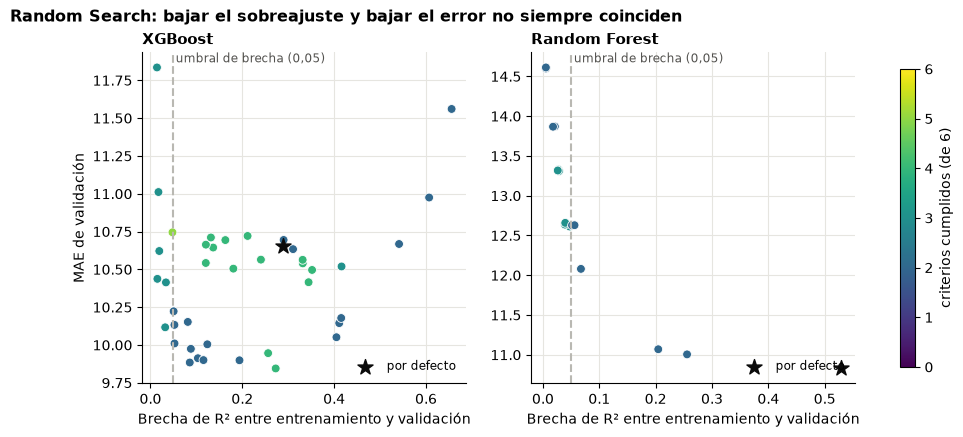

In [10]:
# ---------- Error contra sobreajuste: cada punto es un candidato del Random Search
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
for ax, t in zip(axes, ['xgb', 'rf']):
    r = RANDOM[t]
    p = ax.scatter(r['brecha_R2'], r['MAE'], c=r['criterios'], cmap='viridis', vmin=0, vmax=6, s=40, edgecolor='white', linewidth=0.6)
    ax.scatter([DEFECTO[t]['brecha_R2']], [DEFECTO[t]['MAE']], marker='*', s=130, color='#0b0b0b', label='por defecto', zorder=5)
    ax.axvline(UMBRALES['brecha_R2'], color='#b9b8b2', linestyle='--')
    ax.text(UMBRALES['brecha_R2'] + 0.005, ax.get_ylim()[1], 'umbral de brecha (0,05)', fontsize=8.5, va='top', color='#52514e')
    ax.legend(frameon=False, fontsize=8.5, loc='lower right')
    ax.set_title(NOMBRES[t], loc='left', fontsize=11, fontweight='bold')
    ax.set_xlabel('Brecha de R² entre entrenamiento y validación'); ax.set_ylabel('MAE de validación' if t == 'xgb' else '')
    ax.grid(color='#e6e5e0', linewidth=0.8); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.colorbar(p, ax=axes, label='criterios cumplidos (de 6)', shrink=0.9)
fig.suptitle('Random Search: bajar el sobreajuste y bajar el error no siempre coinciden', x=0.01, ha='left', fontsize=11.5, fontweight='bold')
fig.savefig(IMAGENES / '5_1_random_error_contra_sobreajuste.png', dpi=110, bbox_inches='tight'); plt.show()

**Lectura de la figura.** Cada punto es un candidato. Los que tienen poca brecha (a la izquierda del umbral de 0,05) casi siempre tienen un MAE mayor que los de la derecha: bajar el sobreajuste y bajar el error no coinciden. En Random Forest el costo es muy alto (el bosque podado pierde más de un punto de MAE); en XGBoost los candidatos con 5 criterios quedan justo al borde del umbral, sin margen.

## 5.3 Fase 2: Grid Search acotado

In [11]:
# ---------- Fase 2: Grid Search acotado alrededor del mejor candidato del Random Search (la malla se arma sola desde ese candidato)
B = {t: mejor(RANDOM[t])['params'] for t in NOMBRES}
def alrededor(v, f):                          # un valor continuo: el valor y sus vecinos multiplicativos
    return [round(v / f, 4), round(v, 4), round(v * f, 4)]

ESPACIO_GRID = {
    'ridge': {'modelo__alpha': np.logspace(np.log10(B['ridge']['modelo__alpha']) - 1, np.log10(B['ridge']['modelo__alpha']) + 1, 5)},
    'xgb': {'modelo__max_depth': [B['xgb']['modelo__max_depth'] - 1, B['xgb']['modelo__max_depth'], B['xgb']['modelo__max_depth'] + 1],
            'modelo__learning_rate': alrededor(B['xgb']['modelo__learning_rate'], 1.5),
            'modelo__n_estimators': [int(B['xgb']['modelo__n_estimators'] * f) for f in (0.7, 1.0, 1.4)],
            'modelo__min_child_weight': alrededor(B['xgb']['modelo__min_child_weight'], 3),
            # lo que el Random Search dejó fijo en su mejor candidato queda fijo también aquí
            **{k: [v] for k, v in B['xgb'].items() if k not in ['modelo__max_depth', 'modelo__learning_rate', 'modelo__n_estimators', 'modelo__min_child_weight']}},
    'rf': {'modelo__min_samples_leaf': [8, B['rf']['modelo__min_samples_leaf'], 20],
           'modelo__max_features': [0.65, round(B['rf']['modelo__max_features'], 4), 1.0],
           **{k: [v] for k, v in B['rf'].items() if k not in ['modelo__min_samples_leaf', 'modelo__max_features']}},
}
for t in NOMBRES:
    n = int(np.prod([len(v) for v in ESPACIO_GRID[t].values()]))
    libres = {k.replace('modelo__', ''): [round(float(x), 4) if x is not None else None for x in v] for k, v in ESPACIO_GRID[t].items() if len(v) > 1}
    print(f'{NOMBRES[t]:14s} | {n:3d} combinaciones | {libres}')

Ridge          |   5 combinaciones | {'alpha': [0.0001, 0.0004, 0.0013, 0.0042, 0.0133]}
Random Forest  |   9 combinaciones | {'min_samples_leaf': [8.0, 13.0, 20.0], 'max_features': [0.65, 0.8655, 1.0]}
XGBoost        |  81 combinaciones | {'max_depth': [2.0, 3.0, 4.0], 'learning_rate': [0.0505, 0.0757, 0.1135], 'n_estimators': [244.0, 350.0, 489.0], 'min_child_weight': [0.5305, 1.5914, 4.7741]}


**Nota.** La malla no se escribe a mano: se arma sola alrededor del mejor candidato del Random Search (el que cumple más criterios). Cada hiperparámetro continuo toma tres valores (el del candidato y sus vecinos, multiplicando y dividiendo por un factor); la profundidad toma el valor y sus dos vecinos enteros; el número de árboles toma el 70%, el 100% y el 140%. Lo que el Random Search dejó fijo en su mejor candidato (muestreo de filas y variables, regularización L1 y L2 y pérdida) queda fijo también aquí. Así el Grid explora solo la vecindad de lo que ya funcionó, que es su papel: afinar, no explorar. En XGBoost se afinan los cuatro hiperparámetros que más mueven el compromiso entre ajuste y sobreajuste (profundidad, tasa de aprendizaje, número de árboles y peso mínimo de hoja), con 3 valores cada uno: 81 combinaciones. En Random Forest, 9 combinaciones alrededor de la poda del candidato elegido. El `min_child_weight` de 0,53 queda por debajo del rango del Random Search (1 a 60): una malla alrededor del mejor valor puede salirse del rango original, y eso es justamente lo que se quiere ver.

In [12]:
GRID = {}
for t in ['ridge', 'xgb', 'rf']:
    busq = GridSearchCV(armar(t), ESPACIO_GRID[t], n_jobs=(4 if t == 'ridge' else 1), **PARAMS_COMUNES)
    GRID[t] = buscar(f'{t}_grid', busq, DATOS[t])
    m, r = mejor(GRID[t]), mejor(RANDOM[t])
    print(f"{NOMBRES[t]:14s} | {len(GRID[t]):3d} combinaciones | búsqueda {GRID[t]['segundos_total'].iloc[0]:.0f} s | "
          f"mejor del Grid: MAE {m['MAE']:.3f}, {int(m['criterios'])} criterios (el Random: MAE {r['MAE']:.3f}, {int(r['criterios'])} criterios)")

Ridge          |   5 combinaciones | búsqueda 11 s | mejor del Grid: MAE 11.467, 3 criterios (el Random: MAE 11.467, 3 criterios)
XGBoost        |  81 combinaciones | búsqueda 370 s | mejor del Grid: MAE 10.729, 5 criterios (el Random: MAE 10.745, 5 criterios)
Random Forest  |   9 combinaciones | búsqueda 846 s | mejor del Grid: MAE 12.613, 3 criterios (el Random: MAE 12.613, 3 criterios)


In [13]:
# ---------- Resumen del Grid y, en Random Forest, el efecto de cada valor de la poda
filas = []
for t in NOMBRES:
    res = GRID[t]
    filas.append({'modelo': NOMBRES[t], 'combinaciones': len(res), 'con 5 o más criterios': int((res['criterios'] >= 5).sum()),
                  'máximo de criterios': int(res['criterios'].max()), 'menor MAE': res['MAE'].min(), 'menor brecha_R2': res['brecha_R2'].min()})
display(pd.DataFrame(filas).set_index('modelo'))
display(GRID['rf'][['param_modelo__min_samples_leaf', 'param_modelo__max_features'] + COLS].sort_values(['param_modelo__min_samples_leaf', 'param_modelo__max_features']).reset_index(drop=True))

,combinaciones,con 5 o más criterios,máximo de criterios,menor MAE,menor brecha_R2
modelo,,,,,
Ridge,5,0,3,11.467,0.005
Random Forest,9,0,3,12.596,0.036
XGBoost,81,9,5,10.487,0.014


,param_modelo__min_samples_leaf,param_modelo__max_features,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios
0,8,0.650,12.609,0.046,16.698,0.306,0.058,34.211,4.866,2
1,8,0.866,12.596,0.050,16.725,0.304,0.060,34.140,4.871,2
2,8,1.000,12.600,0.052,16.743,0.302,0.061,34.139,4.866,2
3,13,0.650,12.631,0.042,16.722,0.304,0.046,34.287,4.876,3
4,13,0.866,12.613,0.043,16.742,0.303,0.047,34.260,4.923,3
5,13,1.000,12.613,0.048,16.757,0.301,0.048,34.244,4.931,3
6,20,0.650,12.654,0.045,16.746,0.302,0.036,34.398,4.942,3
7,20,0.866,12.638,0.042,16.767,0.300,0.037,34.354,4.957,3
8,20,1.000,12.637,0.048,16.781,0.299,0.037,34.344,4.969,3


**Lectura del Grid Search.**

- **Ridge.** Las 5 combinaciones dan el mismo MAE (11,467). Con Random y con Grid, `alpha` no cambia nada.
- **XGBoost.** El mejor del Grid (MAE 10,729) mejora al del Random Search (10,745) en 0,016, mucho menos que el ruido entre folds (0,054): afinar alrededor del mejor punto no aporta nada medible. Varias combinaciones de la vecindad cumplen los mismos 5 criterios, y entre ellas las diferencias de MAE (de 10,729 a 10,742) son una fracción del ruido: dan igual. El Grid fue barato (370 s por 81 combinaciones) porque trabaja alrededor de árboles de profundidad 2 a 4, mucho más rápidos que los del Random Search (1.194 s por 40).
- **Random Forest.** El mejor punto del Grid es el mismo del Random Search (es el centro de la malla), y ninguna de las 9 combinaciones cumple más de 3 criterios. La tabla muestra el mecanismo: con hojas de 8 canciones la brecha queda sobre el límite (0,058 a 0,061) y con 13 o más baja de 0,05, pero el MAE casi no cambia (12,60 a 12,64) y R² queda cerca de 0,30. En este modelo la poda cumple la brecha **destruyendo** la capacidad de predecir.
- **H3:** se cumple. El Grid afina menos de lo que aportó el Random Search, y en este caso no supera el ruido.

## 5.4 Todas las fases juntas

El **ruido** es la desviación estándar del MAE entre los 5 folds: una diferencia menor que el ruido no se considera real. La fila de cada fase es el mejor candidato según la regla de la sección 1.2.

In [14]:
def veredicto(dif, ruido):
    return 'mejora' if dif < -ruido else 'empeora' if dif > ruido else 'sin efecto'

filas = []
for t in NOMBRES:
    base = DEFECTO[t]
    for fase, res in [('0 defecto', None), ('1 random', RANDOM[t]), ('2 grid', GRID[t])]:
        r = base if res is None else mejor(res)
        filas.append({'modelo': NOMBRES[t], 'fase': fase, 'candidatos': 1 if res is None else len(res), 'MAE': r['MAE'], 'ruido': r['ruido'], 'RMSE': r['RMSE'],
                      'R2': r['R2'], 'brecha_R2': r['brecha_R2'], 'MAE_exitos': r['MAE_exitos'], 'brecha_cuartiles': r['brecha_cuartiles'],
                      'criterios': int(r['criterios']), 'cambio MAE vs defecto': r['MAE'] - base['MAE'],
                      'veredicto': veredicto(r['MAE'] - base['MAE'], base['ruido']),
                      'menor MAE de la fase': base['MAE'] if res is None else res['MAE'].min(),
                      'segundos': r['segundos_total'] if res is None else res['segundos_total'].iloc[0]})
FASES = pd.DataFrame(filas).set_index(['modelo', 'fase'])
display(FASES)

candidatos    MAE  ruido   RMSE    R2  brecha_R2  MAE_exitos  brecha_cuartiles  criterios  cambio MAE vs defecto   veredicto  \
modelo        fase                                                                                                                                      
Ridge         0 defecto           1 11.467  0.046 16.133 0.352      0.005      32.746             4.131          3                  0.000  sin efecto   
              1 random           20 11.467  0.046 16.133 0.352      0.005      32.746             4.131          3                 -0.000  sin efecto   
              2 grid              5 11.467  0.046 16.133 0.352      0.005      32.746             4.131          3                 -0.000  sin efecto   
Random Forest 0 defecto           1 10.828  0.079 15.622 0.393      0.528      30.014             3.613          2                  0.000  sin efecto   
              1 random           16 12.613  0.043 16.742 0.303      0.047      34.260             4.923          3                  1.784     empeora   
              2 grid              9 12.613  0.043 16.742 0.303      0.047      34.260             4.923          3                  1.784     empeora   
XGBoost       0 defecto           1 10.655  0.085 15.663 0.390      0.288      29.002             3.752          2                  0.000  sin efecto   
              1 random           40 10.745  0.069 15.441 0.407      0.048      31.311             3.769          5                  0.090     empeora   
              2 grid             81 10.729  0.054 15.431 0.407      0.049      31.370             3.757          5                  0.074  sin efecto   

                         menor MAE de la fase  segundos  
modelo        fase                                       
Ridge         0 defecto                11.467     5.737  
              1 random                 11.467    42.640  
              2 grid                   11.467    11.422  
Random Forest 0 defecto                10.828   251.964  
              1 random                 11.005   952.131  
              2 grid                   12.596   845.897  
XGBoost       0 defecto                10.655     3.785  
              1 random                  9.845 1,194.283  
              2 grid                   10.487   369.689

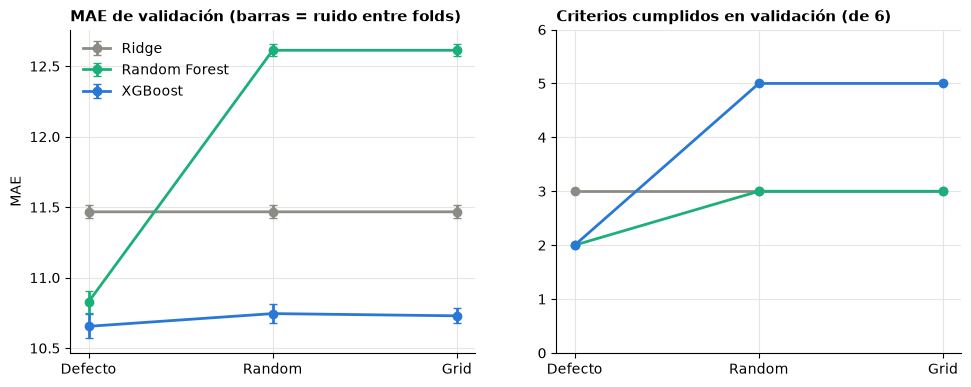

In [15]:
# ---------- Figura: MAE de validación (con el ruido entre folds) y criterios cumplidos en cada fase
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
colores = {'Ridge': '#8c8b86', 'Random Forest': '#1baf7a', 'XGBoost': '#2a78d6'}
fases = ['0 defecto', '1 random', '2 grid']
for modelo, c in colores.items():
    g = FASES.loc[modelo].loc[fases]
    axes[0].errorbar(range(3), g['MAE'], yerr=g['ruido'], marker='o', color=c, capsize=3, linewidth=2, label=modelo)
    axes[1].plot(range(3), g['criterios'], marker='o', color=c, linewidth=2, label=modelo)
axes[0].set_title('MAE de validación (barras = ruido entre folds)', loc='left', fontsize=10.5, fontweight='bold'); axes[0].set_ylabel('MAE')
axes[1].set_title('Criterios cumplidos en validación (de 6)', loc='left', fontsize=10.5, fontweight='bold'); axes[1].set_yticks(range(0, 7))
for ax in axes:
    ax.set_xticks(range(3)); ax.set_xticklabels(['Defecto', 'Random', 'Grid']); ax.grid(color='#e6e5e0'); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
axes[0].legend(frameon=False)
fig.savefig(IMAGENES / '5_2_fases_de_optimizacion.png', dpi=110, bbox_inches='tight'); plt.show()

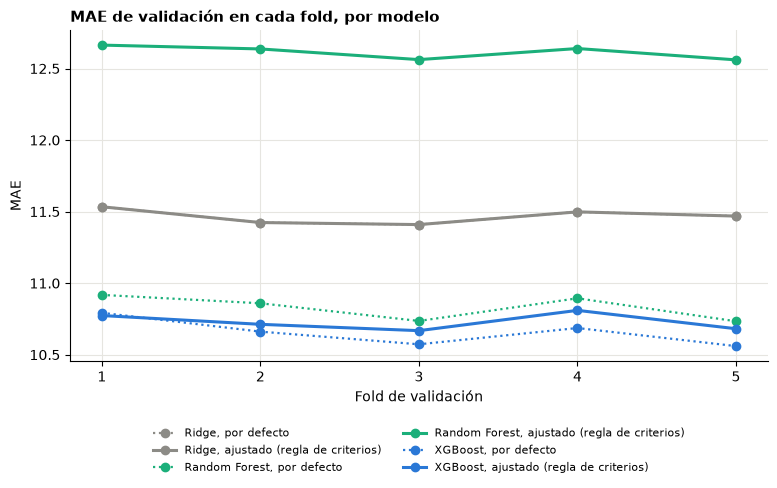

In [16]:
# ---------- Figura: estabilidad por fold. MAE de validación en cada uno de los 5 folds, con parámetros por defecto (punteado) y con el mejor candidato de la búsqueda (sólido)
fig, ax = plt.subplots(figsize=(9, 4.3))
for modelo, t, c in [('Ridge', 'ridge', '#8c8b86'), ('Random Forest', 'rf', '#1baf7a'), ('XGBoost', 'xgb', '#2a78d6')]:
    elegido = mejor(GRID[t])
    por_defecto = [DEFECTO[t][f'split{k}_test_MAE'] for k in range(5)]
    ajustado = [elegido[f'split{k}_test_MAE'] for k in range(5)]
    ax.plot(range(1, 6), por_defecto, marker='o', color=c, linestyle=':', linewidth=1.6, label=f'{modelo}, por defecto')
    ax.plot(range(1, 6), ajustado, marker='o', color=c, linewidth=2.2, label=f'{modelo}, ajustado (regla de criterios)')
ax.set_xticks(range(1, 6)); ax.set_xlabel('Fold de validación'); ax.set_ylabel('MAE')
ax.set_title('MAE de validación en cada fold, por modelo', loc='left', fontsize=10.5, fontweight='bold')
ax.legend(frameon=False, fontsize=8, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.17)); ax.grid(color='#e6e5e0'); ax.set_axisbelow(True)
for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '5_4_estabilidad_por_fold.png', dpi=110, bbox_inches='tight'); plt.show()

**Lectura (estabilidad).** Las líneas casi no se cruzan: en cada uno de los 5 folds, XGBoost y Random Forest por defecto quedan por debajo de Ridge, y el Random Forest podado (el que elige la regla de criterios) queda por encima de todos. Las líneas de cada modelo suben y bajan juntas, lo que indica que el MAE varía con la dificultad de cada fold y no con el modelo. Un modelo estable es el que mantiene su lugar en todos los folds; aquí ninguno lo pierde.

**Lectura (H1 y H2).**

- **Ridge:** las tres fases dan 11,467. Ajustar no cambia nada que se distinga del ruido (0,046).
- **Random Forest:** el candidato que la regla elige **empeora** el MAE de 10,828 a 12,613 (+1,784, 40 veces el ruido de 0,043) a cambio de bajar la brecha de R² de 0,528 a 0,047. Ni siquiera el menor MAE de las búsquedas (11,005 en el Random y 12,596 en el Grid) supera a los hiperparámetros por defecto. **H2 se cumple y es más fuerte de lo esperado:** regularizar baja el sobreajuste, pero no baja el error, lo sube.
- **XGBoost:** el candidato elegido tiene un MAE de 10,729 contra 10,655 por defecto (+0,074, dentro del ruido de 0,085), pero sube de 2 a 5 criterios cumplidos: R² de 0,390 a 0,407, RMSE de 15,663 a 15,431 y brecha de R² de 0,288 a 0,049. Aquí el ajuste no compra menos error: compra **menos sobreajuste** al mismo error. Si en cambio se busca solo el menor MAE, el Random Search llega a 9,845, 0,810 menos que el valor por defecto (unas 9,5 veces el ruido), pero con pérdida absoluta y una brecha de 0,273.
- **H1** se cumple a medias: ajustar mejora el MAE de XGBoost solo si se busca el MAE (pérdida absoluta); si se busca cumplir criterios, el MAE no mejora, y en Ridge no cambia nada.

## 5.5 Aporte de los ensambles: un árbol solo contra bosque y boosting

Random Forest (bagging) y XGBoost (boosting) son ensambles de árboles. Para demostrar que el ensamble aporta algo hay que compararlos con **un árbol de decisión solo**, ajustado con el mismo cuidado (Grid Search sobre profundidad y tamaño mínimo de hoja, mismos 5 folds, misma preparación que Random Forest). Un árbol solo suele tener alta varianza: cambia mucho de un fold a otro y sobreajusta. Si el ensamble funciona, debe bajar el error y estabilizarlo.

In [17]:
# ---------- Referencia: un árbol de decisión solo, con su propia búsqueda (misma preparación y mismos folds que Random Forest)
from sklearn.tree import DecisionTreeRegressor
arbol = Pipeline([('pre', clone(PRE['rf'])), ('modelo', DecisionTreeRegressor(random_state=SEMILLA))])
espacio_arbol = {'modelo__max_depth': [3, 5, 8, 12, None], 'modelo__min_samples_leaf': [1, 10, 40]}
ARBOL = buscar('arbol_grid', GridSearchCV(arbol, espacio_arbol, n_jobs=4, **PARAMS_COMUNES), X_train)

def piscina(t):
    return pd.concat([pd.DataFrame([DEFECTO[t]]).infer_objects(), RANDOM[t], GRID[t]], ignore_index=True)

filas = [('Árbol de decisión solo (menor MAE de 15 combinaciones)', ARBOL.sort_values('MAE').iloc[0]),
         ('Random Forest, parámetros por defecto', DEFECTO['rf']),
         ('XGBoost, parámetros por defecto', DEFECTO['xgb']),
         ('Random Forest (menor MAE de sus búsquedas)', piscina('rf').sort_values('MAE').iloc[0]),
         ('XGBoost (menor MAE de sus búsquedas)', piscina('xgb').sort_values('MAE').iloc[0])]
ENSAMBLES = pd.DataFrame([{'modelo': n, 'MAE': r['MAE'], 'ruido (desv. entre folds)': r['ruido'], 'RMSE': r['RMSE'], 'R2': r['R2'], 'brecha_R2': r['brecha_R2']} for n, r in filas]).set_index('modelo')
ENSAMBLES['MAE menos que el árbol solo (%)'] = (1 - ENSAMBLES['MAE'] / ENSAMBLES.iloc[0]['MAE']) * 100
display(ENSAMBLES)
print('Árbol solo, mejor combinación:', ARBOL.sort_values('MAE').iloc[0]['params'])

,MAE,ruido (desv. entre folds),RMSE,R2,brecha_R2,MAE menos que el árbol solo (%)
modelo,,,,,,
Árbol de decisión solo (menor MAE de 15 combinaciones),11.906,0.079,16.814,0.296,0.153,0.000
"Random Forest, parámetros por defecto",10.828,0.079,15.622,0.393,0.528,9.049
"XGBoost, parámetros por defecto",10.655,0.085,15.663,0.390,0.288,10.507
Random Forest (menor MAE de sus búsquedas),10.828,0.079,15.622,0.393,0.528,9.049
XGBoost (menor MAE de sus búsquedas),9.845,0.069,15.430,0.407,0.273,17.310


Árbol solo, mejor combinación: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 40}


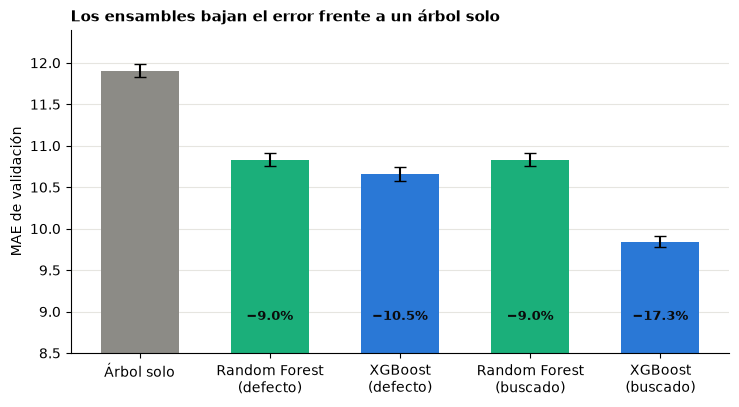

In [18]:
# ---------- Figura: un árbol solo contra bosque y boosting (MAE de validación, barras = ruido entre folds)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
etiquetas = ['Árbol solo', 'Random Forest\n(defecto)', 'XGBoost\n(defecto)', 'Random Forest\n(buscado)', 'XGBoost\n(buscado)']
colores_b = ['#8c8b86', '#1baf7a', '#2a78d6', '#1baf7a', '#2a78d6']
barras = ax.bar(etiquetas, ENSAMBLES['MAE'], yerr=ENSAMBLES['ruido (desv. entre folds)'], color=colores_b, capsize=4, width=0.6)
for b, pct in zip(barras, ENSAMBLES['MAE menos que el árbol solo (%)']):
    if pct > 0:
        ax.text(b.get_x() + b.get_width() / 2, 8.9, f'−{pct:.1f}%', ha='center', color='#0b0b0b', fontsize=9.5, fontweight='bold')
ax.set_ylim(8.5, 12.4); ax.set_ylabel('MAE de validación')
ax.set_title('Los ensambles bajan el error frente a un árbol solo', loc='left', fontsize=10.5, fontweight='bold')
ax.grid(axis='y', color='#e6e5e0'); ax.set_axisbelow(True)
for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '5_3_ensambles.png', dpi=110, bbox_inches='tight'); plt.show()

**Lectura (aporte de los ensambles).**

- **Un árbol solo llega a un MAE de 11,906** (R² 0,296), con su mejor combinación: sin límite de profundidad y hojas de al menos 40 canciones.
- **El bosque (bagging) lo baja a 10,828**, 9,0% menos, y sube el R² a 0,393. Promediar muchos árboles distintos compensa los errores individuales: reduce la varianza.
- **El boosting lo baja a 10,655 con parámetros por defecto** (10,5% menos) y **a 9,845 tras buscar** (17,3% menos, R² 0,407). Cada árbol corrige lo que faltaba: reduce el sesgo, y la búsqueda de hiperparámetros agrega todavía más.
- **El ensamble aporta, pero no estabiliza el error entre folds:** la desviación del MAE entre los 5 folds es de 0,079 en el árbol solo, 0,079 en el bosque y entre 0,069 y 0,085 en XGBoost. Los tres varían parecido entre folds; lo que cambia es el nivel del error.
- **Un matiz sobre la brecha:** el árbol solo, con hojas de 40 canciones, tiene una brecha de R² de 0,153, menor que la del bosque (0,528), porque cada árbol del bosque crece sin límite. El bosque sobreajusta más el entrenamiento y aun así predice mejor en validación.
- **Este apartado compara bagging y boosting contra un árbol solo.** La mezcla de varios modelos (promedios de semillas y de dos tipos de pérdida) se prueba en la sección 7.3.

---
# 6. Evaluación en prueba de los finalistas

## 6.1 Quiénes son los finalistas

Hasta aquí no se ha usado la prueba. De todos los candidatos probados (defecto, Random y Grid) pasan a la prueba, por modelo, dos: el que cumple **más criterios** (la regla de la sección 1.2) y el de **menor MAE** de validación. Si son el mismo candidato, se evalúa uno. Es la única vez que se mira la prueba.

In [19]:
# ---------- Finalistas: todos los candidatos de cada modelo juntos
POOL = {}
for t in NOMBRES:
    d = pd.DataFrame([DEFECTO[t]]).infer_objects().assign(fase='0 defecto')
    POOL[t] = pd.concat([d, RANDOM[t].assign(fase='1 random'), GRID[t].assign(fase='2 grid')], ignore_index=True)

FINALISTAS = {}
for t in NOMBRES:
    a, b = mejor(POOL[t]), POOL[t].sort_values('MAE').iloc[0]
    FINALISTAS[(t, 'más criterios')] = a
    if a['params_json'] != b['params_json']:
        FINALISTAS[(t, 'menor MAE')] = b
filas = [{'finalista': f'{NOMBRES[t]} ({tipo})', 'fase': r['fase'], 'MAE valid.': r['MAE'], 'ruido': r['ruido'], 'criterios en validación': int(r['criterios']), 'hiperparámetros': r['params']}
         for (t, tipo), r in FINALISTAS.items()]
pd.DataFrame(filas).set_index('finalista')

,fase,MAE valid.,ruido,criterios en validación,hiperparámetros
finalista,,,,,
Ridge (más criterios),2 grid,11.467,0.046,3,{'modelo__alpha': 0.00013289448722869187}
Random Forest (más criterios),1 random,12.613,0.043,3,"{'modelo__max_depth': 22, 'modelo__max_features': 0.8655000144869414, 'modelo__max_sam..."
Random Forest (menor MAE),0 defecto,10.828,0.079,2,{}
XGBoost (más criterios),2 grid,10.729,0.054,5,"{'modelo__colsample_bytree': 0.9026260635443968, 'modelo__learning_rate': 0.1135, 'mod..."
XGBoost (menor MAE),1 random,9.845,0.069,4,"{'modelo__colsample_bytree': 0.8154616197341622, 'modelo__learning_rate': 0.0224136985..."


**Nota.** Son cinco finalistas. En Ridge el que cumple más criterios y el de menor MAE son el mismo. En Random Forest el de menor MAE es el **modelo con parámetros por defecto**: ninguna combinación de las 25 probadas lo mejoró. En XGBoost el de menor MAE es el candidato de pérdida absoluta del Random Search.

## 6.2 Prueba: los seis criterios

Cada finalista se vuelve a entrenar con **todo** el entrenamiento y se mide una vez en la prueba. El criterio 4 (brecha de R²) compara el R² en entrenamiento con el de prueba, como en la EV2.

In [20]:
# ---------- Entrenar cada finalista con todo el entrenamiento y medirlo en la prueba (una sola vez)
AJUSTADOS, filas = {}, []
for (t, tipo), r in FINALISTAS.items():
    Xtr, Xte = (X_train_xgb, X_test_xgb) if t == 'xgb' else (X_train, X_test)
    t0 = time.time()
    pipe = armar(t).set_params(**r['params']).fit(Xtr, y_train)
    seg = time.time() - t0
    m = puntuar(pipe, Xte, y_test)
    m['brecha_R2'] = r2_score(y_train, pipe.predict(Xtr)) - m['R2']
    AJUSTADOS[(t, tipo)] = pipe
    c = [m['R2'] >= UMBRALES['R2'], m['RMSE'] <= UMBRALES['RMSE'], m['MAE'] <= UMBRALES['MAE'], m['brecha_R2'] <= UMBRALES['brecha_R2'],
         m['MAE_exitos'] <= UMBRALES['MAE_exitos'], m['brecha_cuartiles'] <= UMBRALES['brecha_cuartiles']]
    filas.append({'finalista': f'{NOMBRES[t]} ({tipo})', 'R2': m['R2'], 'RMSE': m['RMSE'], 'MAE': m['MAE'], 'brecha_R2': m['brecha_R2'],
                  'MAE_exitos': m['MAE_exitos'], 'brecha_cuartiles': m['brecha_cuartiles'], 'criterios': sum(c), 'no cumple': [n for n, ok in zip(range(1, 7), c) if not ok],
                  'segundos': seg})
PRUEBA = pd.DataFrame(filas).set_index('finalista')
umbral = pd.DataFrame([{'R2': '>= 0,40', 'RMSE': f"<= {UMBRALES['RMSE']:.2f}", 'MAE': f"<= {UMBRALES['MAE']:.2f}", 'brecha_R2': '<= 0,05', 'MAE_exitos': '<= 20', 'brecha_cuartiles': '<= 5'}], index=['UMBRAL'])
display(umbral)
display(PRUEBA)

C:\Users\usuario\Desktop\SpotifyTracks\.venv\Lib\site-packages\xgboost\core.py:569: UserWarning: [01:13:13] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles
UMBRAL,">= 0,40",<= 15.51,<= 13.46,"<= 0,05",<= 20,<= 5


,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,no cumple,segundos
finalista,,,,,,,,,
Ridge (más criterios),0.348,16.267,11.516,0.009,32.821,4.408,3,"[1, 2, 5]",1.131
Random Forest (más criterios),0.296,16.896,12.735,0.045,34.515,5.458,2,"[1, 2, 5, 6]",21.775
Random Forest (menor MAE),0.388,15.756,10.846,0.533,29.950,3.940,2,"[1, 2, 4, 5]",56.366
XGBoost (más criterios),0.397,15.645,10.839,0.054,31.534,4.075,2,"[1, 2, 4, 5]",0.726
XGBoost (menor MAE),0.393,15.688,9.946,0.263,28.435,4.004,2,"[1, 2, 4, 5]",11.029


**Lectura.**

- **Ningún finalista cumple los seis criterios en la prueba.** El mayor número de criterios cumplidos es 3 (Ridge: MAE, brecha de R² y cuartiles). XGBoost (más criterios) cumple 2: el MAE (10,839) y los cuartiles de género (4,075).
- **De 5 criterios en validación a 2 en la prueba.** El candidato de XGBoost tenía R² 0,407, RMSE 15,431 y brecha 0,049 en validación; en la prueba tiene 0,397, 15,645 y 0,054. Los tres criterios se cumplían en validación por márgenes de 0,007, 0,082 y 0,001, y la prueba los dejó afuera por 0,003, 0,132 y 0,004. No es una falla del procedimiento: el candidato se eligió por ser el mejor de 121 en validación, así que su cifra de validación es algo optimista (la prueba se separó justamente para detectar esto).
- **El criterio 4 (brecha) casi se cumple** (0,054 contra 0,05), un cambio grande respecto de la EV2 (0,265).
- **XGBoost de pérdida absoluta** da el menor error de la prueba (MAE 9,946), pero su brecha es 0,263 y no cumple R² ni RMSE.
- **Random Forest podado** (más criterios) es el peor en prueba: R² 0,296 y MAE 12,735.

In [21]:
# ---------- ¿Mejoró respecto de la EV2 (hiperparámetros por defecto)? Misma prueba, mismas medidas
filas = []
for t in NOMBRES:
    e = met_ev2['modelos'][t]
    filas.append({'modelo': NOMBRES[t], 'MAE EV2': e['MAE test'], 'RMSE EV2': e['RMSE test'], 'R2 EV2': e['R2 test'],
                  'brecha R2 EV2': e['R2 train'] - e['R2 test'], 'MAE exitos EV2': e['MAE test exitos'], 'brecha cuartiles EV2': e['brecha MAE cuartiles de genero']})
EV2_PRUEBA = pd.DataFrame(filas).set_index('modelo')
ahora = PRUEBA.loc[[f'{NOMBRES[t]} ({tp})' for (t, tp) in FINALISTAS if tp == 'más criterios']]
ahora.index = [NOMBRES[t] for (t, tp) in FINALISTAS if tp == 'más criterios']
comparacion = pd.concat([EV2_PRUEBA[['MAE EV2', 'MAE exitos EV2']], ahora[['MAE', 'MAE_exitos']]], axis=1)
comparacion['cambio MAE'] = comparacion['MAE'] - comparacion['MAE EV2']
display(EV2_PRUEBA)
display(comparacion)

,MAE EV2,RMSE EV2,R2 EV2,brecha R2 EV2,MAE exitos EV2,brecha cuartiles EV2
modelo,,,,,,
Ridge,11.516,16.267,0.348,0.009,32.821,4.408
Random Forest,10.846,15.756,0.388,0.533,29.950,3.940
XGBoost,10.643,15.788,0.386,0.265,29.360,3.984


,MAE EV2,MAE exitos EV2,MAE,MAE_exitos,cambio MAE
Ridge,11.516,32.821,11.516,32.821,-0.000
Random Forest,10.846,29.950,12.735,34.515,1.889
XGBoost,10.643,29.360,10.839,31.534,0.196


**¿Mejoró respecto de la EV2?** Depende de qué se mida.

- **Ridge:** no cambió (MAE 11,516 en ambas).
- **Random Forest** (el que cumple más criterios): empeoró, de 10,846 a 12,735 (+1,889) de MAE. Para esa regla, el Random Forest de la EV2 con parámetros por defecto es mejor.
- **XGBoost** (el que cumple más criterios): el MAE subió de 10,643 a 10,839 (+0,196) y el error en éxitos de 29,360 a 31,534, pero la generalización mejoró mucho: la brecha de R² bajó de 0,265 a 0,054, el R² subió de 0,386 a 0,397 y el RMSE bajó de 15,788 a 15,645.

Con la regla elegida el ajuste no compró menos error, compró un modelo que generaliza mejor, a un costo pequeño en MAE.

---
# 7. Intentos de mejora: pesos, variables nuevas, mezcla de modelos y el artista

## 7.0 Por qué se hacen y cómo se miden

Después de la sección 6, el XGBoost elegido por la regla cumple 2 criterios en la prueba y deja otros tres a milésimas de distancia (R² por 0,003, RMSE por 0,132 y brecha por 0,004); el criterio 5 (éxitos) queda lejos. Antes de cerrar la selección se plantean cuatro intentos de mejora. Cada uno tiene una razón y una expectativa que se escribe **antes de medir**, y todos se miden con la misma disciplina:

- Primero en **validación cruzada**, con los hiperparámetros del modelo elegido **sin volver a buscarlos**, para saber si la idea ayuda sin gastar la prueba.
- A la **prueba** pasa una sola vez cada idea que se midió, solo para confirmar.
- Una diferencia de MAE menor que el **ruido** entre folds (0,054 en el modelo elegido) se considera "sin efecto".

| Intento | Por qué se prueba | Qué se espera |
|---|---|---|
| **7.1 Pesos por popularidad** (H6) | El criterio 5 falla porque los éxitos son pocos (el 1% de las canciones) y casi no pesan en el error que se minimiza | Que baje el error en éxitos, pero a costa de R² y RMSE, que ya están justos |
| **7.2 Variables nuevas** (H7) | El género es lo que más usa el modelo; la media de su género y cuánto se aleja la canción de su género son información que el modelo podría usar mejor | Poco o nada: los árboles ya pueden formar esas combinaciones |
| **7.3 Mezcla de modelos** (H8) | Los dos XGBoost se equivocan de forma distinta: el de pérdida cuadrática predice la media (cuida R² y RMSE) y el de pérdida absoluta predice la mediana (cuida el MAE) | Que el promedio mejore R², RMSE y MAE a la vez, y que la brecha de sobreajuste suba porque el de pérdida absoluta memoriza más el entrenamiento |
| **7.4 Extra: el artista** (H9) | En el EDA el artista explicaba más variación que el género y se excluyó del modelo; esto mide cuánto costó esa decisión | Una mejora grande, pero que dependa de que el artista tenga historial |

In [22]:
# ---------- Referencias comunes de los intentos: el modelo elegido y el de menor MAE (pérdida absoluta)
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.model_selection import KFold

PARAMS_XGB = FINALISTAS[('xgb', 'más criterios')]['params']      # modelo elegido por la regla (pérdida cuadrática)
PARAMS_ABS = FINALISTAS[('xgb', 'menor MAE')]['params']          # el de menor MAE (pérdida absoluta)
base_ref = mejor(GRID['xgb'])                                     # su resultado en validación cruzada

def fila_prueba(nombre, p_tr, p_te, X_te):
    # Mide unas predicciones en la prueba con los seis criterios (la brecha compara el R2 de entrenamiento con el de prueba)
    m = medidas(p_te, X_te, y_test)
    m['brecha_R2'] = r2_score(y_train, p_tr) - m['R2']
    c = [m['R2'] >= UMBRALES['R2'], m['RMSE'] <= UMBRALES['RMSE'], m['MAE'] <= UMBRALES['MAE'], m['brecha_R2'] <= UMBRALES['brecha_R2'],
         m['MAE_exitos'] <= UMBRALES['MAE_exitos'], m['brecha_cuartiles'] <= UMBRALES['brecha_cuartiles']]
    return {'experimento': nombre, 'R2': m['R2'], 'RMSE': m['RMSE'], 'MAE': m['MAE'], 'brecha_R2': m['brecha_R2'], 'MAE_exitos': m['MAE_exitos'],
            'brecha_cuartiles': m['brecha_cuartiles'], 'criterios': sum(c), 'no cumple': [n for n, ok in zip(range(1, 7), c) if not ok]}

FILAS_PRUEBA = [{'experimento': 'modelo elegido (referencia)', **PRUEBA.loc['XGBoost (más criterios)', ['R2', 'RMSE', 'MAE', 'brecha_R2', 'MAE_exitos', 'brecha_cuartiles', 'criterios', 'no cumple']].to_dict()}]
print('Referencia (validación):', {c: round(float(base_ref[c]), 3) for c in COLS})

Referencia (validación): {'MAE': 10.729, 'ruido': 0.054, 'RMSE': 15.431, 'R2': 0.407, 'brecha_R2': 0.049, 'MAE_exitos': 31.37, 'brecha_cuartiles': 3.757, 'criterios': 5.0}


**Nota.** Estas referencias se definen una vez porque las usan los cuatro intentos. `fila_prueba` mide cualquier conjunto de predicciones con los mismos seis criterios que se usaron con los finalistas, para que todos los intentos sean comparables entre sí y con el modelo elegido.

## 7.1 Pesos por popularidad (H6)

**Por qué.** El único criterio que ningún candidato cumple es el 5 (error en canciones de popularidad ≥ 70). Los hiperparámetros no lo arreglan porque los éxitos son muy pocos (657 de 17.155 canciones de prueba) y casi no pesan en el error que el modelo minimiza. Una idea es **darles más peso al entrenar** (`sample_weight`): equivocarse en un éxito cuesta más.

**Qué se espera.** Que baje el error en éxitos pero a costa de R² y RMSE, que ya están justos. Esto **no es un hiperparámetro de búsqueda**: cambia cómo se define el problema, así que se trata como exploración y se mide solo en validación.

In [23]:
# ---------- Peso extra para las canciones de éxito: w = 1 + k para popularidad >= 70, 1 para el resto
filas = []
for k in [0, 2, 5, 10, 20]:
    w = (1 + k * (y_train >= CORTE_EXITO)).values.astype(float)
    busq = GridSearchCV(armar('xgb').set_params(**PARAMS_XGB), {}, n_jobs=1, **PARAMS_COMUNES)
    r = buscar(f'xgb_pesos_{k}', busq, X_train_xgb, modelo__sample_weight=w).iloc[0]
    filas.append({'peso extra por éxito (k)': k, **{c: r[c] for c in COLS}, 'cumple': [n for n, c in zip(range(1, 7), ['c1 R2', 'c2 RMSE', 'c3 MAE', 'c4 brecha R2', 'c5 MAE exitos', 'c6 cuartiles']) if r[c]]})
PESOS = pd.DataFrame(filas).set_index('peso extra por éxito (k)')
display(PESOS)

,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,cumple
peso extra por éxito (k),,,,,,,,,
0,10.729,0.054,15.431,0.407,0.049,31.370,3.757,5,"[1, 2, 3, 4, 6]"
2,10.839,0.048,15.899,0.371,0.059,23.910,3.548,2,"[3, 6]"
5,11.097,0.055,16.688,0.307,0.062,18.805,3.620,3,"[3, 5, 6]"
10,11.492,0.063,17.635,0.226,0.059,14.854,3.819,3,"[3, 5, 6]"
20,12.148,0.084,18.872,0.114,0.055,11.347,4.305,3,"[3, 5, 6]"


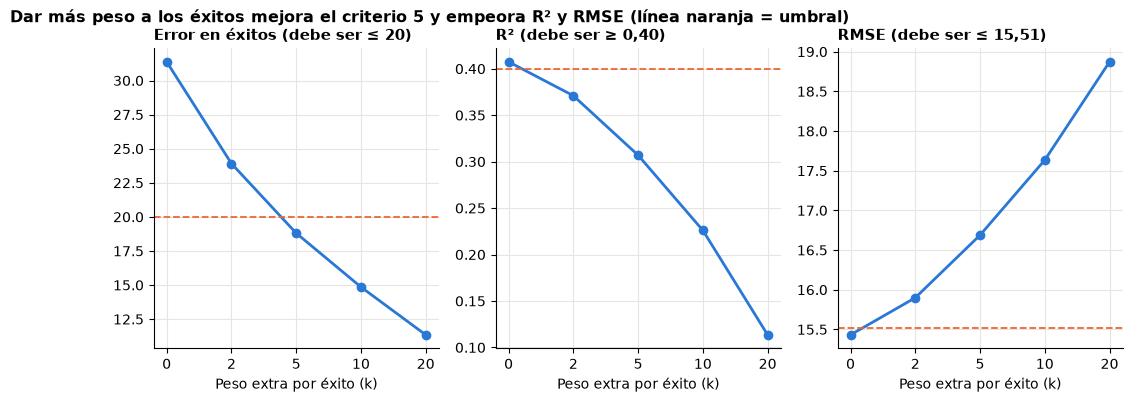

In [24]:
# ---------- Figura: lo que se gana (error en éxitos) y lo que se pierde (R² y RMSE) al darles más peso a los éxitos
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.9))
for ax, col, umbral, titulo in [(axes[0], 'MAE_exitos', UMBRALES['MAE_exitos'], 'Error en éxitos (debe ser ≤ 20)'),
                                (axes[1], 'R2', UMBRALES['R2'], 'R² (debe ser ≥ 0,40)'),
                                (axes[2], 'RMSE', UMBRALES['RMSE'], 'RMSE (debe ser ≤ 15,51)')]:
    ax.plot(range(len(PESOS)), PESOS[col], marker='o', color='#2a78d6', linewidth=2)
    ax.axhline(umbral, color='#eb6834', linestyle='--', linewidth=1.3)
    ax.set_xticks(range(len(PESOS))); ax.set_xticklabels(PESOS.index); ax.set_xlabel('Peso extra por éxito (k)')
    ax.set_title(titulo, loc='left', fontsize=10.5, fontweight='bold'); ax.grid(color='#e6e5e0'); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.suptitle('Dar más peso a los éxitos mejora el criterio 5 y empeora R² y RMSE (línea naranja = umbral)', x=0.01, ha='left', fontsize=11.5, fontweight='bold')
fig.savefig(IMAGENES / '7_1_pesos_por_popularidad.png', dpi=110, bbox_inches='tight'); plt.show()

**Resultado.** La expectativa se cumple, y la conclusión es negativa:

| Peso extra (k) | Error en éxitos (criterio 5) | R² | RMSE | Criterios cumplidos |
|---|---|---|---|---|
| 0 (sin pesos) | 31,370 | 0,407 | 15,431 | 5 |
| 2 | 23,910 | 0,371 | 15,899 | 2 |
| 5 | **18,805** | 0,307 | 16,688 | 3 |
| 10 | 14,854 | 0,226 | 17,635 | 3 |
| 20 | 11,347 | 0,114 | 18,872 | 3 |

Con un peso de 5 el criterio 5 **sí se cumple** (18,805 contra 20), pero el modelo pierde los criterios 1, 2 y 4: el R² cae de 0,407 a 0,307, el RMSE sube a 16,688 y la brecha pasa a 0,062. Cuanto más pesan los éxitos, mejor se predicen y peor se predice todo lo demás, porque el modelo empieza a decir "éxito" para muchas canciones que se le parecen y no lo son. Con ningún peso se cumplen más de 3 criterios, y sin pesos eran 5. **H6 no se cumple:** con estas variables, el criterio 5 es incompatible con los criterios 1 y 2. No es un problema de hiperparámetros ni de pesos, sino de que el audio, el género y los metadatos no contienen suficiente información para reconocer un éxito. **Los pesos se descartan** y quedan anotados como un experimento que no sirvió.

## 7.2 Variables nuevas a partir del género (H7)

**Por qué.** El género es lo que más usa el modelo (31,5% de la importancia, sección 9). Se construyen dos tipos de variables que el modelo podría aprovechar: la **popularidad media del género** como variable numérica (además de la categoría) y, para seis variables de audio (`danceability`, `energy`, `loudness`, `acousticness`, `valence` y `tempo`), **cuánto se aleja la canción del promedio de su género** (por ejemplo, cuánto más bailable que lo típico de su género).

**Qué se espera.** Poco o nada, porque los árboles ya pueden formar esas combinaciones por sí solos. Las variables se calculan **dentro del `Pipeline`**, así que en cada fold aprenden solo de las canciones de entrenamiento de ese fold (sin fuga).

In [25]:
COL_AUDIO = ['danceability', 'energy', 'loudness', 'acousticness', 'valence', 'tempo']

class RelativoAlGenero(BaseEstimator, TransformerMixin):
    # Agrega, para cada variable de audio, cuánto se aleja la canción del promedio de su género (el promedio se aprende solo del entrenamiento)
    def __init__(self, columnas=COL_AUDIO):
        self.columnas = columnas
    def fit(self, X, y=None):
        self.medias_ = X[self.columnas].groupby(X['track_genre'].astype(str).values).mean()
        return self
    def transform(self, X):
        X = X.copy(); g = X['track_genre'].astype(str)
        for c in self.columnas:
            X[f'{c}_menos_genero'] = X[c].values - g.map(self.medias_[c]).values
        return X

def codificador():
    return TargetEncoder(target_type='continuous', smooth='auto', cv=KFold(n_splits=5, shuffle=True, random_state=SEMILLA))

def variante(media_genero=False, relativo=False, artista=False):
    # El pipeline del modelo elegido (preparación de la EV2) más las variables extra que se pidan
    pasos = [('relativo', RelativoAlGenero())] if relativo else []
    partes = [('base', clone(PRE['xgb']), list(X_train.columns))]
    if relativo:
        partes.append(('relativo', 'passthrough', [f'{c}_menos_genero' for c in COL_AUDIO]))
    if media_genero:
        partes.append(('media_genero', codificador(), ['track_genre']))
    if artista:
        partes.append(('artista', codificador(), ['artista']))
    pre = ColumnTransformer(partes, verbose_feature_names_out=True).set_output(transform='pandas')
    modelo = XGBRegressor(enable_categorical=True, device=DISPOSITIVO, tree_method='hist', random_state=SEMILLA, n_jobs=1)
    return Pipeline(pasos + [('pre', pre), ('modelo', modelo)]).set_params(**PARAMS_XGB)

EXPERIMENTOS = {'variables: media del género': dict(media_genero=True),
                'variables: desviación respecto del género': dict(relativo=True),
                'variables: las dos': dict(media_genero=True, relativo=True)}
VAL_EXP = {}
filas = [{'experimento': 'modelo elegido (referencia)', **{c: base_ref[c] for c in COLS}}]
for nombre, kw in EXPERIMENTOS.items():
    VAL_EXP[nombre] = buscar('xgb_exp_' + nombre.split(': ')[1].replace(' ', '_').replace('é', 'e').replace('ó', 'o'),
                             GridSearchCV(variante(**kw), {}, n_jobs=1, **PARAMS_COMUNES), X_train_xgb).iloc[0]
    filas.append({'experimento': nombre, **{c: VAL_EXP[nombre][c] for c in COLS}})
TABLA_VAR = pd.DataFrame(filas).set_index('experimento')
TABLA_VAR['cambio de MAE'] = TABLA_VAR['MAE'] - TABLA_VAR.loc['modelo elegido (referencia)', 'MAE']
TABLA_VAR['veredicto (ruido de la referencia)'] = [veredicto(d, base_ref['ruido']) for d in TABLA_VAR['cambio de MAE']]
display(TABLA_VAR)

,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,cambio de MAE,veredicto (ruido de la referencia)
experimento,,,,,,,,,,
modelo elegido (referencia),10.729,0.054,15.431,0.407,0.049,31.370,3.757,5,0.000,sin efecto
variables: media del género,10.730,0.064,15.432,0.407,0.050,31.313,3.758,5,0.001,sin efecto
variables: desviación respecto del género,10.719,0.054,15.426,0.408,0.052,31.261,3.771,4,-0.010,sin efecto
variables: las dos,10.709,0.069,15.418,0.408,0.052,31.249,3.761,4,-0.020,sin efecto


**Nota.** `variante()` arma el mismo pipeline del modelo elegido y le agrega las columnas nuevas; el `TargetEncoder` de la media del género usa validación cruzada interna (cross fitting), como en la EV2, para que la media de un género no incluya la propia canción. Los hiperparámetros son los del modelo elegido, sin volver a buscarlos.

In [26]:
# ---------- A la prueba pasa solo la mejor combinación según la regla (más criterios; en empate, menor MAE), una sola vez
mejor_vars = max(EXPERIMENTOS, key=lambda n: (VAL_EXP[n]['criterios'], -VAL_EXP[n]['MAE']))
pipe_vars = variante(**EXPERIMENTOS[mejor_vars]).fit(X_train_xgb, y_train)
FILAS_PRUEBA.append(fila_prueba(f'{mejor_vars} (mejor en validación)', pipe_vars.predict(X_train_xgb), pipe_vars.predict(X_test_xgb), X_test_xgb))
print('Mejor combinación en validación:', mejor_vars)
display(pd.DataFrame(FILAS_PRUEBA[-2:]).set_index('experimento'))

Mejor combinación en validación: variables: media del género


,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,no cumple
experimento,,,,,,,,
modelo elegido (referencia),0.397,15.645,10.839,0.054,31.534,4.075,2,"[1, 2, 4, 5]"
variables: media del género (mejor en validación),0.398,15.627,10.822,0.053,31.506,4.033,2,"[1, 2, 4, 5]"


**Resultado.** Las variables nuevas **no cambian nada**. En validación, la media del género da un MAE de 10,730 (+0,001), la desviación respecto del género 10,719 (−0,010) y las dos juntas 10,709 (−0,020), contra 10,729 del modelo elegido y un ruido de 0,054: las tres quedan "sin efecto". En la prueba, la mejor (la media del género) da MAE 10,822 contra 10,839, R² 0,398 y los mismos 2 criterios. **H7 no se cumple**: el modelo ya tenía el género como categoría y las variables de audio, y un árbol puede formar esas combinaciones por sí solo. La idea se descarta y queda anotada como un experimento que no sirvió, con la ventaja de que ahora lo sabemos con evidencia en vez de suponerlo.

## 7.3 Mezcla de modelos: XGBoost de pérdida cuadrática y de pérdida absoluta (H8)

**La idea.** Hasta aquí se eligió un solo modelo. Pero los dos mejores XGBoost de las búsquedas se equivocan de forma distinta:

- **A, el elegido (pérdida cuadrática):** castiga el error elevado al cuadrado, así que sus predicciones tienden a la **media**. Cuida el R² y el RMSE, pero los errores grandes lo arrastran. Es un modelo simple (profundidad 3, 244 árboles) y casi no sobreajusta.
- **B, el de menor MAE (pérdida absoluta):** castiga el error tal cual, así que sus predicciones tienden a la **mediana**. Tiene el mejor MAE, pero es mucho más profundo (profundidad 9) y memoriza más el entrenamiento.

La mezcla es un **promedio de predicciones**: la predicción final de cada canción es el promedio de lo que predicen todos los modelos A y todos los modelos B, con el mismo peso para los dos tipos: `(promedio de A + promedio de B) / 2`. Se usan 5 modelos A y 3 modelos B, cada uno con una semilla distinta, porque `subsample` y `colsample_bytree` introducen azar y cada semilla da un modelo algo diferente. Promediar varios modelos reduce la varianza; mezclar dos tipos de pérdida combina dos formas de equivocarse que no coinciden, y por eso parte del error se compensa.

**Cómo se evita la fuga de datos.** Los 8 modelos se entrenan solo con las canciones de entrenamiento de cada fold, y se evalúan en las del fold que no vieron. Los pesos de la mezcla son fijos (50% y 50%): nadie los ajustó mirando los datos. La prueba solo se usa para medir.

**Qué se espera.** Que la mezcla mejore R², RMSE y MAE a la vez frente a A solo, y que la brecha de sobreajuste suba (porque B memoriza más). Se mide también cada pieza por separado: promediar solo semillas de A, B solo, y la mezcla.

In [27]:
# ---------- Mezcla: A (el elegido, pérdida cuadrática) con 5 semillas y B (pérdida absoluta) con 3 semillas
SEMILLAS_A, SEMILLAS_B = [42, 1, 2, 3, 4], [42, 1, 2]

def ajustar(params, Xtr, ytr, semilla):
    return armar('xgb').set_params(**params, modelo__random_state=semilla).fit(Xtr, ytr)

def mezclas(modelos_a, modelos_b, X):
    pa = np.mean([m.predict(X) for m in modelos_a], axis=0)
    pb = np.mean([m.predict(X) for m in modelos_b], axis=0)
    return {'A: elegido (1 semilla)': modelos_a[0].predict(X), 'A: promedio de 5 semillas': pa,
            'B: pérdida absoluta (1 semilla)': modelos_b[0].predict(X), 'A + B: promedio de los dos tipos': (pa + pb) / 2}

ruta = BUSQUEDAS / 'xgb_mezclas.csv'
if ruta.exists() and not RECALCULAR:
    POR_FOLD = pd.read_csv(ruta)
else:
    filas, t0 = [], time.time()
    for k, (i_tr, i_va) in enumerate(FOLDS):
        Xtr, Xva, ytr, yva = X_train_xgb.iloc[i_tr], X_train_xgb.iloc[i_va], y_train.iloc[i_tr], y_train.iloc[i_va]
        ma = [ajustar(PARAMS_XGB, Xtr, ytr, s) for s in SEMILLAS_A]
        mb = [ajustar(PARAMS_ABS, Xtr, ytr, s) for s in SEMILLAS_B]
        pred_tr, pred_va = mezclas(ma, mb, Xtr), mezclas(ma, mb, Xva)
        for nombre in pred_va:
            m = medidas(pred_va[nombre], Xva, yva)
            m.update({'R2_train': r2_score(ytr, pred_tr[nombre]), 'mezcla': nombre, 'fold': k})
            filas.append(m)
    POR_FOLD = pd.DataFrame(filas)
    POR_FOLD['segundos_total'] = time.time() - t0
    POR_FOLD.to_csv(ruta, index=False)

g = POR_FOLD.groupby('mezcla', sort=False)
MEZ = pd.DataFrame({'MAE': g['MAE'].mean(), 'ruido': g['MAE'].std(ddof=0), 'RMSE': g['RMSE'].mean(), 'R2': g['R2'].mean(),
                    'brecha_R2': g['R2_train'].mean() - g['R2'].mean(), 'MAE_exitos': g['MAE_exitos'].mean(), 'brecha_cuartiles': g['brecha_cuartiles'].mean()})
MEZ['criterios'] = ((MEZ['R2'] >= UMBRALES['R2']).astype(int) + (MEZ['RMSE'] <= UMBRALES['RMSE']) + (MEZ['MAE'] <= UMBRALES['MAE']) + (MEZ['brecha_R2'] <= UMBRALES['brecha_R2'])
                    + (MEZ['MAE_exitos'] <= UMBRALES['MAE_exitos']) + (MEZ['brecha_cuartiles'] <= UMBRALES['brecha_cuartiles'])).astype(int)
MEZ['cambio de MAE vs A (1 semilla)'] = MEZ['MAE'] - MEZ.loc['A: elegido (1 semilla)', 'MAE']
display(MEZ)

,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,cambio de MAE vs A (1 semilla)
mezcla,,,,,,,,,
A: elegido (1 semilla),10.729,0.054,15.431,0.407,0.049,31.370,3.757,5,0.000
A: promedio de 5 semillas,10.707,0.059,15.403,0.410,0.049,31.300,3.742,5,-0.022
B: pérdida absoluta (1 semilla),9.845,0.069,15.430,0.407,0.273,28.305,3.848,4,-0.884
A + B: promedio de los dos tipos,10.172,0.066,15.265,0.420,0.174,29.778,3.769,4,-0.557


**Nota.** `mezclas()` calcula, para unos datos dados, las cuatro variantes con los mismos modelos ya entrenados: A con una semilla, A promediado, B con una semilla y la mezcla `(A + B) / 2`. Cada fold entrena los 8 modelos desde cero con sus canciones de entrenamiento y se miden con las mismas funciones de las secciones anteriores.

**Resultado en validación.**

- **Promediar 5 semillas de A** baja el MAE a 10,707 (−0,022, dentro del ruido) y sube apenas R² y RMSE (0,410 y 15,403): reduce un poco la varianza y nada más.
- **B solo** tiene el menor MAE (9,845) pero una brecha de 0,273, la expectativa.
- **A + B** da MAE 10,172 (−0,557, unas 10 veces el ruido), R² 0,420 y RMSE 15,265: **mejor que A en las tres medidas**, tal como se esperaba. A cambio, su brecha es 0,174 y cumple 4 criterios (le fallan la brecha y el error en éxitos), contra los 5 de A.

In [28]:
# ---------- Prueba (una sola vez): se entrenan los 8 modelos con todo el entrenamiento y se miden las dos mezclas
ma = [ajustar(PARAMS_XGB, X_train_xgb, y_train, s) for s in SEMILLAS_A]
mb = [ajustar(PARAMS_ABS, X_train_xgb, y_train, s) for s in SEMILLAS_B]
mez_tr, mez_te = mezclas(ma, mb, X_train_xgb), mezclas(ma, mb, X_test_xgb)
for nombre in ['A: promedio de 5 semillas', 'A + B: promedio de los dos tipos']:
    FILAS_PRUEBA.append(fila_prueba('mezcla: ' + nombre, mez_tr[nombre], mez_te[nombre], X_test_xgb))
display(pd.DataFrame([FILAS_PRUEBA[0]] + FILAS_PRUEBA[-2:]).set_index('experimento'))
with pd.option_context('display.float_format', lambda v: f'{v:.5f}'):
    display(pd.DataFrame(FILAS_PRUEBA[-2:]).set_index('experimento')[['R2', 'RMSE', 'brecha_R2']])

,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,no cumple
experimento,,,,,,,,
modelo elegido (referencia),0.397,15.645,10.839,0.054,31.534,4.075,2,"[1, 2, 4, 5]"
mezcla: A: promedio de 5 semillas,0.400,15.608,10.809,0.053,31.452,4.037,2,"[1, 2, 4, 5]"
mezcla: A + B: promedio de los dos tipos,0.408,15.499,10.271,0.170,29.966,3.963,4,"[4, 5]"


,R2,RMSE,brecha_R2
experimento,,,
mezcla: A: promedio de 5 semillas,0.39965,15.60765,0.05305
mezcla: A + B: promedio de los dos tipos,0.40797,15.49913,0.16961


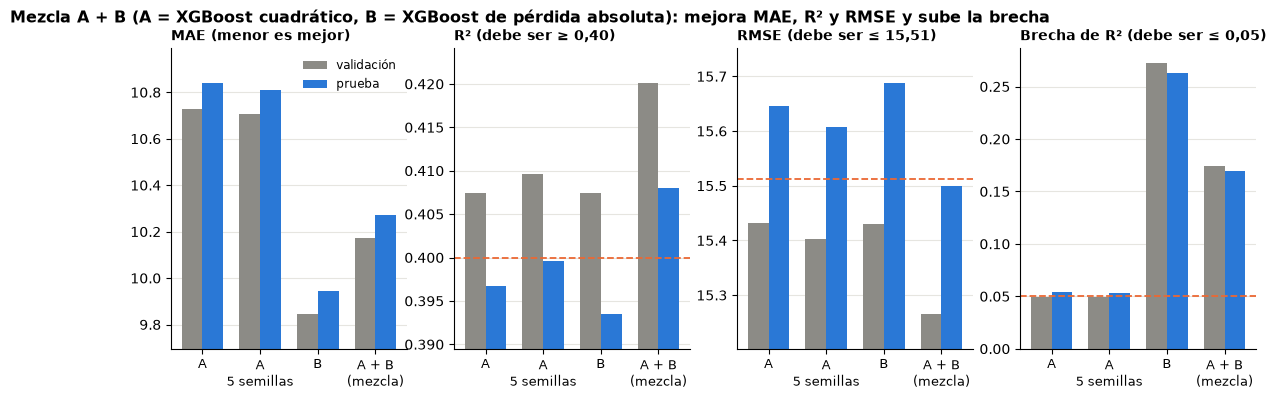

In [29]:
# ---------- Figura: las cuatro variantes en validación cruzada y en la prueba (línea naranja = umbral)
prueba_exp = pd.DataFrame(FILAS_PRUEBA).set_index('experimento')
en_prueba = {'A': PRUEBA.loc['XGBoost (más criterios)'], 'A\n5 semillas': prueba_exp.loc['mezcla: A: promedio de 5 semillas'],
             'B': PRUEBA.loc['XGBoost (menor MAE)'], 'A + B\n(mezcla)': prueba_exp.loc['mezcla: A + B: promedio de los dos tipos']}
en_valid = dict(zip(en_prueba, MEZ.index))
fig, axes = plt.subplots(1, 4, figsize=(14, 3.9))
for ax, col, titulo, umbral in [(axes[0], 'MAE', 'MAE (menor es mejor)', None), (axes[1], 'R2', 'R² (debe ser ≥ 0,40)', UMBRALES['R2']),
                                (axes[2], 'RMSE', 'RMSE (debe ser ≤ 15,51)', UMBRALES['RMSE']), (axes[3], 'brecha_R2', 'Brecha de R² (debe ser ≤ 0,05)', UMBRALES['brecha_R2'])]:
    x = np.arange(len(en_prueba))
    ax.bar(x - 0.18, [MEZ.loc[en_valid[n], col] for n in en_prueba], width=0.36, color='#8c8b86', label='validación')
    ax.bar(x + 0.18, [en_prueba[n][col] for n in en_prueba], width=0.36, color='#2a78d6', label='prueba')
    if umbral is not None:
        ax.axhline(umbral, color='#eb6834', linestyle='--', linewidth=1.3)
    ax.set_xticks(x); ax.set_xticklabels(list(en_prueba), fontsize=9)
    valores = [MEZ.loc[en_valid[n], col] for n in en_prueba] + [en_prueba[n][col] for n in en_prueba] + ([umbral] if umbral is not None else [])
    margen = (max(valores) - min(valores)) * 0.15
    if col != 'brecha_R2':                                   # el eje no parte de cero para que se vea la diferencia (en la brecha sí)
        ax.set_ylim(min(valores) - margen, max(valores) + margen)
    ax.set_title(titulo, loc='left', fontsize=10, fontweight='bold'); ax.grid(axis='y', color='#e6e5e0'); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
axes[0].legend(frameon=False, fontsize=8.5, loc='upper right')
fig.suptitle('Mezcla A + B (A = XGBoost cuadrático, B = XGBoost de pérdida absoluta): mejora MAE, R² y RMSE y sube la brecha', x=0.01, ha='left', fontsize=11.5, fontweight='bold')
fig.savefig(IMAGENES / '7_3_mezcla_de_modelos.png', dpi=110, bbox_inches='tight'); plt.show()

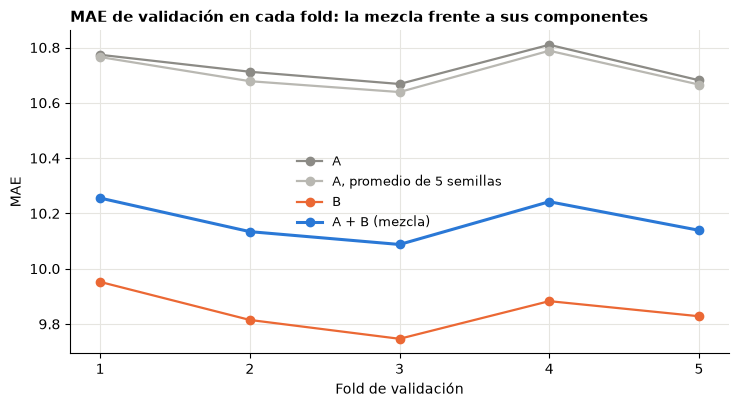

Folds en que la mezcla supera a A: 5 de 5


In [30]:
# ---------- Figura: estabilidad por fold (MAE de validación de cada variante en cada uno de los 5 folds)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
pivot = POR_FOLD.pivot(index='fold', columns='mezcla', values='MAE')
estilo = {'A: elegido (1 semilla)': ('#8c8b86', 'A'), 'A: promedio de 5 semillas': ('#b9b8b2', 'A, promedio de 5 semillas'),
          'B: pérdida absoluta (1 semilla)': ('#eb6834', 'B'), 'A + B: promedio de los dos tipos': ('#2a78d6', 'A + B (mezcla)')}
for col, (c, etiqueta) in estilo.items():
    ax.plot(pivot.index + 1, pivot[col], marker='o', color=c, linewidth=2.2 if 'A + B' in col else 1.6, label=etiqueta)
ax.set_xticks(range(1, 6)); ax.set_xlabel('Fold de validación'); ax.set_ylabel('MAE')
ax.set_title('MAE de validación en cada fold: la mezcla frente a sus componentes', loc='left', fontsize=10.5, fontweight='bold')
ax.legend(frameon=False, fontsize=9); ax.grid(color='#e6e5e0'); ax.set_axisbelow(True)
for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '7_3_estabilidad_por_fold.png', dpi=110, bbox_inches='tight'); plt.show()
print('Folds en que la mezcla supera a A:', int((pivot['A + B: promedio de los dos tipos'] < pivot['A: elegido (1 semilla)']).sum()), 'de 5')

**Lectura (estabilidad de la mezcla).** La mezcla (azul) queda por debajo de A (gris) en los 5 folds, y B (naranja) por debajo de la mezcla en los 5. Las cuatro líneas suben y bajan juntas, así que el orden no depende de una partición favorable: la mejora de la mezcla es consistente, no un promedio que esconde un fold excepcional.

**Resultado en la prueba.**

| | R² | RMSE | MAE | Brecha R² | MAE en éxitos | Equidad | Criterios |
|---|---|---|---|---|---|---|---|
| Modelo elegido (A, 1 semilla) | 0,397 | 15,645 | 10,839 | **0,054** | 31,534 | 4,075 | 2 |
| A: promedio de 5 semillas | 0,400 | 15,608 | 10,809 | 0,053 | 31,452 | 4,037 | 2 |
| **A + B (la mezcla)** | **0,408** | **15,499** | **10,271** | 0,170 | **29,966** | **3,963** | **4** |

La mezcla **confirma la expectativa**: mejora R² (+0,011), RMSE (−0,146), MAE (−0,568), el error en éxitos (−1,568) y la equidad entre géneros, y cumple 4 criterios (R², RMSE, MAE y equidad); le fallan la brecha (0,170) y el error en éxitos (29,966). Promediar solo semillas de A no cambia nada (R² 0,39965, a 0,00035 del umbral). **H8 se cumple.**

**Por qué sobrevivió a la prueba el modelo mezclado y no el elegido.** A cumplía R² y RMSE en validación por márgenes de 0,007 y 0,082 y los perdió en la prueba por 0,003 y 0,132. La mezcla los cumplía por 0,020 y 0,246 y los conservó. Es la lección del margen de seguridad: un cumplimiento que vale por milésimas no resiste el cambio de datos, uno con margen sí. Aun así, el RMSE de la mezcla pasa el umbral por solo 0,014 (15,499 contra 15,51).

**El costo.** Son ocho modelos que entrenar, guardar y consultar (la predicción de una canción es el promedio de ocho predicciones), y una brecha de sobreajuste de 0,170 contra 0,054: la brecha mide qué tanto mejor le va al modelo en el entrenamiento que en la prueba, y la mezcla incluye a B, que memoriza más. Lo que importa para canciones nuevas es el error en la prueba, y ahí la mezcla es la mejor; pero conviene ser claro con que ganamos precisión y perdimos simplicidad y esa medida de sobreajuste. La decisión de adoptarla se toma en la sección 8.

## 7.4 Extra: el artista, lo que más nos limitó (H9)

**Por qué.** En el EDA el artista explicaba más variación que el género (η² de 0,51 contra 0,35) y se excluyó del modelo por el efecto superestrella y por privacidad (secciones 12.1 y 12.3 del informe). Este diagnóstico mide cuánto costó esa decisión; **no es una solución propuesta.** El artista principal de cada canción (el primero de los créditos) se codifica con su popularidad media **dentro de cada fold**, con las demás canciones del artista en el entrenamiento.

**Qué se espera.** Una mejora grande, que dependa de que el artista tenga otras canciones en el entrenamiento.

In [31]:
# ---------- Diagnóstico del artista: el mismo modelo elegido más la popularidad media del artista principal (codificada dentro de cada fold)
artista_principal = lambda ids: ids['artists'].str.split(';').str[0].values
X_train_art = X_train_xgb.assign(artista=artista_principal(ids_train))
X_test_art = X_test_xgb.assign(artista=artista_principal(ids_test))

val_art = buscar('xgb_exp_artista', GridSearchCV(variante(artista=True), {}, n_jobs=1, **PARAMS_COMUNES), X_train_art).iloc[0]
tabla_art = pd.DataFrame({'modelo elegido (referencia)': base_ref[COLS], 'con el artista': val_art[COLS]}).T
tabla_art['cambio de MAE'] = tabla_art['MAE'] - base_ref['MAE']
display(tabla_art)

pipe_art = variante(artista=True).fit(X_train_art, y_train)
p_art_te = pipe_art.predict(X_test_art)
FILAS_PRUEBA.append(fila_prueba('diagnóstico: artista', pipe_art.predict(X_train_art), p_art_te, X_test_art))
display(pd.DataFrame([FILAS_PRUEBA[0], FILAS_PRUEBA[-1]]).set_index('experimento'))

# ¿Cuánto de lo que gana depende de que el artista ya tenga canciones en el entrenamiento?
conocido = X_test_art['artista'].isin(set(X_train_art['artista'])).values
print(f"Canciones de prueba cuyo artista principal tiene otras canciones en el entrenamiento: {conocido.mean() * 100:.1f}% ({conocido.sum():,} de {len(conocido):,})")
base_te = AJUSTADOS[('xgb', 'más criterios')].predict(X_test_xgb)
display(pd.DataFrame({'canciones': [conocido.sum(), (~conocido).sum()],
                      'MAE modelo elegido': [mean_absolute_error(y_test[conocido], base_te[conocido]), mean_absolute_error(y_test[~conocido], base_te[~conocido])],
                      'MAE con el artista': [mean_absolute_error(y_test[conocido], p_art_te[conocido]), mean_absolute_error(y_test[~conocido], p_art_te[~conocido])]},
                     index=['artista con canciones en el entrenamiento', 'artista sin canciones en el entrenamiento']))

,MAE,ruido,RMSE,R2,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,cambio de MAE
modelo elegido (referencia),10.729,0.054,15.431,0.407,0.049,31.370,3.757,5,0.000
con el artista,8.302,0.043,13.192,0.567,0.163,23.420,2.380,4,-2.427


,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,no cumple
experimento,,,,,,,,
modelo elegido (referencia),0.397,15.645,10.839,0.054,31.534,4.075,2,"[1, 2, 4, 5]"
diagnóstico: artista,0.555,13.434,8.421,0.169,24.187,2.728,4,"[4, 5]"


Canciones de prueba cuyo artista principal tiene otras canciones en el entrenamiento: 89.6% (15,377 de 17,155)


,canciones,MAE modelo elegido,MAE con el artista
artista con canciones en el entrenamiento,15377,10.765,8.054
artista sin canciones en el entrenamiento,1778,11.482,11.592


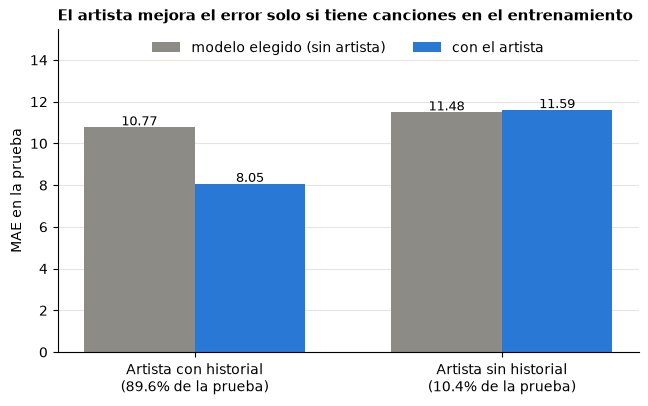

In [32]:
# ---------- Figura: el artista ayuda solo a quienes tienen historial (MAE en la prueba)
grupos = [('Artista con historial\n(%.1f%% de la prueba)' % (conocido.mean() * 100), conocido), ('Artista sin historial\n(%.1f%% de la prueba)' % ((~conocido).mean() * 100), ~conocido)]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(2)
sin_art = [mean_absolute_error(y_test[m], base_te[m]) for _, m in grupos]
con_art = [mean_absolute_error(y_test[m], p_art_te[m]) for _, m in grupos]
b1 = ax.bar(x - 0.18, sin_art, width=0.36, color='#8c8b86', label='modelo elegido (sin artista)')
b2 = ax.bar(x + 0.18, con_art, width=0.36, color='#2a78d6', label='con el artista')
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.1, f'{b.get_height():.2f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([g[0] for g in grupos]); ax.set_ylabel('MAE en la prueba'); ax.set_ylim(0, 15.5)
ax.set_title('El artista mejora el error solo si tiene canciones en el entrenamiento', loc='left', fontsize=10.5, fontweight='bold')
ax.legend(frameon=False, loc='upper center', ncol=2); ax.grid(axis='y', color='#e6e5e0'); ax.set_axisbelow(True)
for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '7_4_artista.png', dpi=110, bbox_inches='tight'); plt.show()

**Resultado.** El artista es **el cambio más grande de todo el trabajo**, mayor que cualquier hiperparámetro, mezcla o variable construida desde el género:

| | R² | RMSE | MAE | MAE en éxitos | Criterios |
|---|---|---|---|---|---|
| Modelo elegido | 0,397 | 15,645 | 10,839 | 31,534 | 2 |
| Con el artista | **0,555** | **13,434** | **8,421** | **24,187** | 4 |

En validación el MAE baja de 10,729 a 8,302 (−2,427, unas 45 veces el ruido). En la prueba cumple 4 criterios (le fallan la brecha, 0,169, y el error en éxitos, que baja a 24,2 pero sigue sobre 20). **H9 se cumple, y con un matiz decisivo:** el 89,6% de las canciones de prueba (15.377 de 17.155) tiene un artista con otras canciones en el entrenamiento, y para ellas el MAE baja de 10,765 a 8,054. Para las 1.778 restantes (artistas sin historial) **no mejora** (11,482 contra 11,592). La ganancia sale de conocer al artista, así que no sirve justo para los artistas nuevos, donde un sello querría apoyarse en el modelo.

**Por qué no se adopta.** El artista se había excluido por el efecto superestrella (el modelo aprende a predecir "popular" para quien ya lo es; no se midió ese sesgo con este modelo) y por privacidad. Este diagnóstico es un **techo informativo**: dice qué información hace falta, no que deba usarse. Decidir si se incorpora es una decisión de negocio y de ética, no un ajuste del modelo.

---
# 8. Selección de la solución óptima

## 8.1 Todos los candidatos, medidos en la prueba

Se reúnen los finalistas de la sección 6 y la mezcla de la sección 7.3. Todos se entrenaron con todo el entrenamiento y se midieron en la prueba, cada uno una sola vez.

In [33]:
# ---------- Candidatos en la prueba: finalistas de la sección 6 y la mezcla A + B de la sección 7.3
columnas = ['R2', 'RMSE', 'MAE', 'brecha_R2', 'MAE_exitos', 'brecha_cuartiles', 'criterios', 'no cumple']
mezcla_fila = pd.DataFrame(FILAS_PRUEBA).set_index('experimento').loc[['mezcla: A + B: promedio de los dos tipos'], columnas]
mezcla_fila.index = ['Mezcla A + B (XGBoost cuadrático + absoluto)']
CANDIDATOS = pd.concat([PRUEBA[columnas], mezcla_fila])
umbral = pd.DataFrame([{'R2': '>= 0,40', 'RMSE': f"<= {UMBRALES['RMSE']:.2f}", 'MAE': f"<= {UMBRALES['MAE']:.2f}", 'brecha_R2': '<= 0,05', 'MAE_exitos': '<= 20', 'brecha_cuartiles': '<= 5'}], index=['UMBRAL'])
display(umbral)
display(CANDIDATOS)

,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles
UMBRAL,">= 0,40",<= 15.51,<= 13.46,"<= 0,05",<= 20,<= 5


,R2,RMSE,MAE,brecha_R2,MAE_exitos,brecha_cuartiles,criterios,no cumple
Ridge (más criterios),0.348,16.267,11.516,0.009,32.821,4.408,3,"[1, 2, 5]"
Random Forest (más criterios),0.296,16.896,12.735,0.045,34.515,5.458,2,"[1, 2, 5, 6]"
Random Forest (menor MAE),0.388,15.756,10.846,0.533,29.950,3.940,2,"[1, 2, 4, 5]"
XGBoost (más criterios),0.397,15.645,10.839,0.054,31.534,4.075,2,"[1, 2, 4, 5]"
XGBoost (menor MAE),0.393,15.688,9.946,0.263,28.435,4.004,2,"[1, 2, 4, 5]"
Mezcla A + B (XGBoost cuadrático + absoluto),0.408,15.499,10.271,0.170,29.966,3.963,4,"[4, 5]"


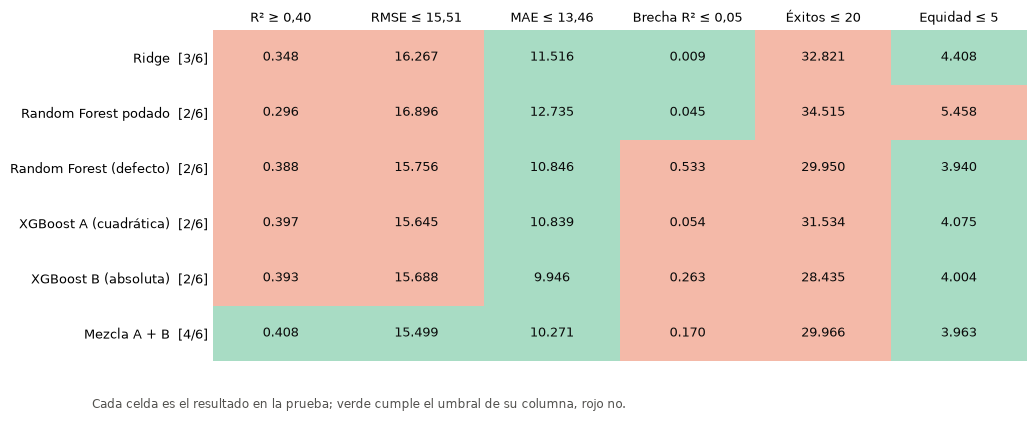

In [34]:
# ---------- Figura: qué criterios cumple cada candidato en la prueba (verde = cumple, rojo = no cumple)
from matplotlib.colors import ListedColormap
cols = ['R2', 'RMSE', 'MAE', 'brecha_R2', 'MAE_exitos', 'brecha_cuartiles']
etiquetas_cols = ['R² ≥ 0,40', 'RMSE ≤ 15,51', 'MAE ≤ 13,46', 'Brecha R² ≤ 0,05', 'Éxitos ≤ 20', 'Equidad ≤ 5']
ok = np.array([[r['R2'] >= UMBRALES['R2'], r['RMSE'] <= UMBRALES['RMSE'], r['MAE'] <= UMBRALES['MAE'], r['brecha_R2'] <= UMBRALES['brecha_R2'],
                r['MAE_exitos'] <= UMBRALES['MAE_exitos'], r['brecha_cuartiles'] <= UMBRALES['brecha_cuartiles']] for _, r in CANDIDATOS.iterrows()])
fig, ax = plt.subplots(figsize=(10.5, 4.3))
ax.imshow(ok, cmap=ListedColormap(['#f4b9a8', '#a8dcc4']), aspect='auto')
for i in range(ok.shape[0]):
    for j, c in enumerate(cols):
        ax.text(j, i, f"{CANDIDATOS.iloc[i][c]:.3f}", ha='center', va='center', fontsize=9.5, color='#0b0b0b')
ax.set_xticks(range(6)); ax.set_xticklabels(etiquetas_cols, fontsize=9); ax.xaxis.tick_top()
NOMBRES_CORTOS = ['Ridge', 'Random Forest podado', 'Random Forest (defecto)', 'XGBoost A (cuadrática)', 'XGBoost B (absoluta)', 'Mezcla A + B']   # mismo orden que CANDIDATOS
nombres_filas = [f'{n}  [{int(k)}/6]' for n, k in zip(NOMBRES_CORTOS, CANDIDATOS['criterios'])]
ax.set_yticks(range(ok.shape[0])); ax.set_yticklabels(nombres_filas, fontsize=9)
for lado in ax.spines.values(): lado.set_visible(False)
ax.tick_params(length=0)
fig.text(0.01, 0.0, 'Cada celda es el resultado en la prueba; verde cumple el umbral de su columna, rojo no.', fontsize=8.5, color='#52514e')
fig.savefig(IMAGENES / '8_1_criterios_por_candidato.png', dpi=110, bbox_inches='tight'); plt.show()

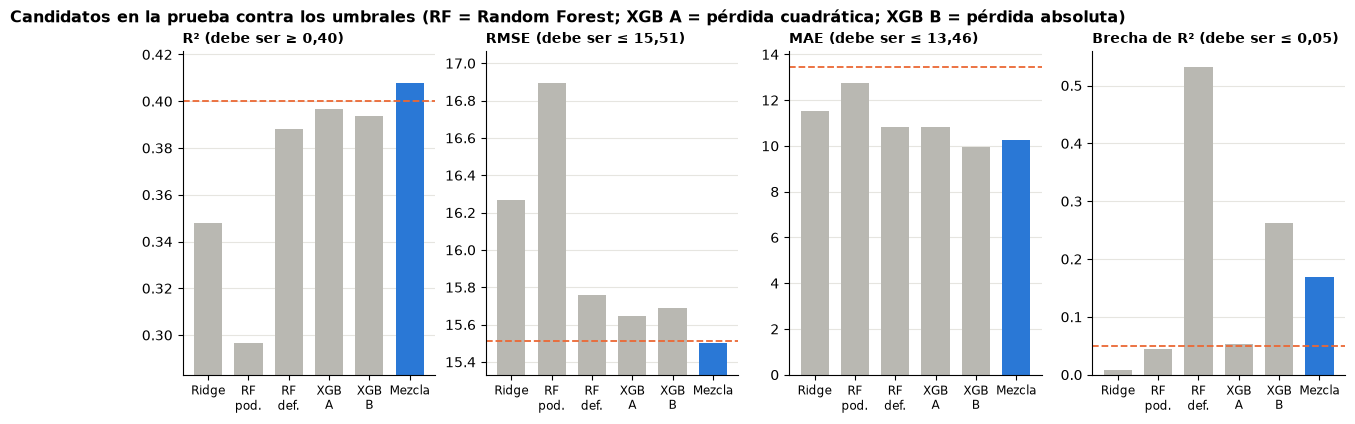

In [35]:
# ---------- Figura: los seis candidatos en las medidas principales (línea naranja = umbral; la mezcla en azul)
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
x = np.arange(len(CANDIDATOS))
colores_c = ['#b9b8b2'] * (len(CANDIDATOS) - 1) + ['#2a78d6']
for ax, col, titulo, umbral in [(axes[0], 'R2', 'R² (debe ser ≥ 0,40)', UMBRALES['R2']), (axes[1], 'RMSE', 'RMSE (debe ser ≤ 15,51)', UMBRALES['RMSE']),
                                (axes[2], 'MAE', 'MAE (debe ser ≤ 13,46)', UMBRALES['MAE']), (axes[3], 'brecha_R2', 'Brecha de R² (debe ser ≤ 0,05)', UMBRALES['brecha_R2'])]:
    ax.bar(x, CANDIDATOS[col], color=colores_c, width=0.7)
    ax.axhline(umbral, color='#eb6834', linestyle='--', linewidth=1.3)
    if col in ('R2', 'RMSE'):
        v = list(CANDIDATOS[col]) + [umbral]; m = (max(v) - min(v)) * 0.12
        ax.set_ylim(min(v) - m, max(v) + m)
    ax.set_xticks(x); ax.set_xticklabels(['Ridge', 'RF\npod.', 'RF\ndef.', 'XGB\nA', 'XGB\nB', 'Mezcla'], fontsize=8.5)
    ax.set_title(titulo, loc='left', fontsize=10, fontweight='bold'); ax.grid(axis='y', color='#e6e5e0'); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.suptitle('Candidatos en la prueba contra los umbrales (RF = Random Forest; XGB A = pérdida cuadrática; XGB B = pérdida absoluta)', x=0.01, ha='left', fontsize=11.5, fontweight='bold')
fig.savefig(IMAGENES / '8_1_candidatos_en_prueba.png', dpi=110, bbox_inches='tight'); plt.show()

**Lectura de las figuras.** El mapa de colores muestra, de un vistazo, qué criterios cumple cada candidato: la mezcla es la única con R² y RMSE en verde a la vez, y es la que más verdes reúne (4 de 6). Las barras muestran por cuánto: la mezcla supera a todos en R² y RMSE; en MAE solo la gana XGBoost B (pérdida absoluta), que a cambio tiene una brecha de 0,263; y en la brecha, Ridge, el Random Forest podado y XGBoost A quedan mejor que la mezcla, que es su costo.

## 8.2 Decisión y justificación

**Se elige la mezcla A + B** (promedio de 5 XGBoost de pérdida cuadrática y 3 XGBoost de pérdida absoluta). Hay dos candidatos serios, y conviene explicar cómo se llegó a la decisión.

**Qué decía la regla.** La regla de la sección 1.2 (más criterios cumplidos en validación) elegía el XGBoost A solo: 5 criterios contra 4 de la mezcla. Pero contar criterios es una regla tosca: trata igual fallar por 0,003 que por 0,05, y en la prueba el orden cambió (A cumple 2 y la mezcla 4).

**Qué dice la evidencia, mirando primero solo la validación.** Sin usar la prueba, la mezcla tiene mejor R² (0,420 contra 0,407), RMSE (15,265 contra 15,431) y MAE (10,172 contra 10,729, unas 10 veces el ruido) y cumple sus umbrales con más margen; solo pierde en la brecha de sobreajuste (0,174 contra 0,049) y en simplicidad. La prueba confirma la misma dirección: R² 0,408 contra 0,397, RMSE 15,499 contra 15,645, MAE 10,271 contra 10,839, error en éxitos 29,966 contra 31,534 y 4 criterios contra 2.

**Por qué se acepta el costo.** La brecha de R² compara el desempeño en el entrenamiento con el de la prueba; sube porque B memoriza más el entrenamiento. Pero lo que le importa a quien use el modelo es el error con canciones nuevas, y ese baja. A cambio se pierde simplicidad: ocho modelos que guardar y consultar.

**Lo que hay que decir con honestidad.**

- **No hay fuga de datos.** Los ocho modelos se entrenan solo con el entrenamiento, los pesos de la mezcla son fijos (50% y 50%) y la prueba solo se usa para medir.
- **Sí hay un pequeño sesgo de selección.** La mezcla se planteó como intento de mejora antes de medirla, pero la regla fijada eligió otro modelo y se decidió adoptarla después de ver que en la prueba también ganaba. Su cifra de prueba deja de ser una estimación perfectamente limpia, aunque el sesgo es acotado: se comparan solo tres o cuatro opciones, no cientos.
- **Pasa el RMSE por muy poco.** 15,499 contra un umbral de 15,51 (0,014). Con otros datos podría quedar afuera.
- **Optimismo heredado.** A y B salieron de elegir al mejor entre muchos candidatos, así que sus cifras de validación están algo infladas, y la mezcla las hereda.

**Alternativas, según lo que se valore.** Si se prefiere un modelo simple y explicable, el XGBoost A solo (MAE 10,839, brecha 0,054). Si lo único que importa es el error absoluto promedio, el XGBoost B solo (MAE 9,946, brecha 0,263).

## 8.3 Guardar la solución final

In [36]:
# ---------- Guardar la mezcla (los 8 modelos ya entrenados con todo el entrenamiento) y sus hiperparámetros
joblib.dump({'modelos_A': ma, 'modelos_B': mb, 'generos': GENEROS,
             'descripcion': 'La prediccion es (promedio de las predicciones de modelos_A + promedio de las de modelos_B) / 2. Los modelos son Pipelines que reciben el genero como categoria nativa.'},
            MODELOS / 'modelo_final_ev3.joblib')
with open(MODELOS / 'modelo_final_ev3.json', 'w', encoding='utf-8') as f:
    json.dump({'modelo': 'Mezcla A + B', 'prediccion': '(promedio de modelos_A + promedio de modelos_B) / 2',
               'hiperparametros_A': PARAMS_XGB, 'hiperparametros_B': PARAMS_ABS, 'semillas_A': SEMILLAS_A, 'semillas_B': SEMILLAS_B, 'dispositivo': DISPOSITIVO,
               'metricas_prueba': {k: float(v) for k, v in CANDIDATOS.loc['Mezcla A + B (XGBoost cuadrático + absoluto)', ['R2', 'RMSE', 'MAE', 'brecha_R2', 'MAE_exitos', 'brecha_cuartiles']].items()}},
              f, ensure_ascii=False, indent=2)
print('Guardado en models/: modelo_final_ev3.joblib (8 modelos) y modelo_final_ev3.json')

Guardado en models/: modelo_final_ev3.joblib (8 modelos) y modelo_final_ev3.json


**Nota.** El modelo final se guarda como un diccionario con los 5 modelos A y los 3 modelos B, cada uno un `Pipeline` completo (preparación más XGBoost). Para predecir se promedian las predicciones de cada grupo y luego los dos promedios, como en el código de la sección 7.3. Se guarda así, y no como una clase propia, para que se pueda cargar sin necesitar este notebook.

---
# 9. Errores e interpretación de la solución final

## 9.1 Error por segmento de popularidad (prueba)

In [37]:
# ---------- Error por segmento de popularidad: mezcla final contra la línea base (predice siempre la media del entrenamiento) y contra el modelo A solo
pred = mez_te['A + B: promedio de los dos tipos']
base = np.full(len(y_test), y_train.mean())
segs = {'Popularidad 0': y_test == 0, 'Popularidad 1 a 69': (y_test > 0) & (y_test < 70), 'Popularidad 70 o más': y_test >= 70}
filas = []
for nombre, mask in segs.items():
    filas.append({'segmento': nombre, 'canciones': int(mask.sum()), 'MAE línea base': mean_absolute_error(y_test[mask], base[mask]),
                  'MAE modelo A solo': mean_absolute_error(y_test[mask], base_te[mask]), 'MAE mezcla final': mean_absolute_error(y_test[mask], pred[mask]),
                  'sesgo de la mezcla (pred - real)': (pred[mask] - y_test[mask]).mean()})
display(pd.DataFrame(filas).set_index('segmento'))

e = np.abs(y_test.values - pred)
puntos = pd.DataFrame({'error medio (MAE)': [e.mean()], 'error mediano': [np.median(e)], '% con error <= 5 puntos': [(e <= 5).mean() * 100],
                       '% con error <= 10 puntos': [(e <= 10).mean() * 100], '% con error <= 20 puntos': [(e <= 20).mean() * 100], '% con error > 30 puntos': [(e > 30).mean() * 100]},
                      index=['mezcla final'])
display(puntos)

,canciones,MAE línea base,MAE modelo A solo,MAE mezcla final,sesgo de la mezcla (pred - real)
segmento,,,,,
Popularidad 0,1316,34.323,25.876,25.503,25.493
Popularidad 1 a 69,15182,14.254,8.640,8.098,-0.897
Popularidad 70 o más,657,41.194,31.534,29.966,-29.966


,error medio (MAE),error mediano,% con error <= 5 puntos,% con error <= 10 puntos,% con error <= 20 puntos,% con error > 30 puntos
mezcla final,10.271,5.773,45.363,66.453,84.296,7.770


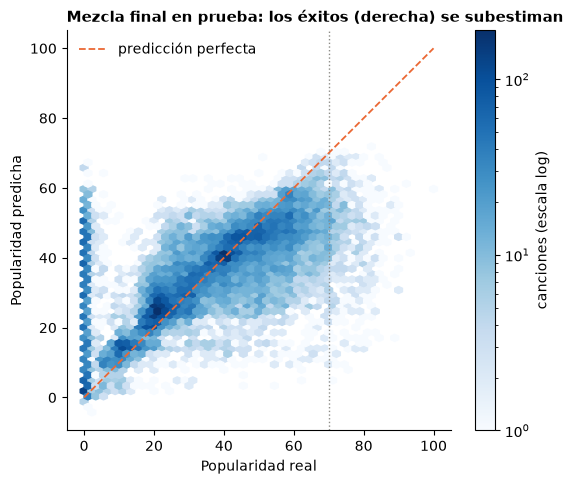

In [38]:
# ---------- Figura: predicción contra valor real (los éxitos quedan por debajo de la diagonal)
fig, ax = plt.subplots(figsize=(6.2, 5.2))
hb = ax.hexbin(y_test, pred, gridsize=45, cmap='Blues', mincnt=1, bins='log')
ax.plot([0, 100], [0, 100], color='#eb6834', linestyle='--', linewidth=1.3, label='predicción perfecta')
ax.axvline(CORTE_EXITO, color='#8c8b86', linestyle=':', linewidth=1)
ax.set_xlabel('Popularidad real'); ax.set_ylabel('Popularidad predicha')
ax.set_title('Mezcla final en prueba: los éxitos (derecha) se subestiman', loc='left', fontsize=10.5, fontweight='bold')
ax.legend(frameon=False, loc='upper left'); fig.colorbar(hb, label='canciones (escala log)')
for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '9_1_prediccion_contra_real.png', dpi=110, bbox_inches='tight'); plt.show()

## 9.2 Qué usa el modelo final

In [39]:
# ---------- Importancia de las variables: ganancia de cada variable en los árboles, promediada entre los modelos de cada tipo y luego entre A y B
def importancia(m):
    nombres = list(m.named_steps['pre'].get_feature_names_out())
    s = pd.Series(m.named_steps['modelo'].get_booster().get_score(importance_type='gain')).reindex(nombres).fillna(0)
    return s / s.sum() * 100

imp_A = pd.concat([importancia(m) for m in ma], axis=1).mean(axis=1)
imp_B = pd.concat([importancia(m) for m in mb], axis=1).mean(axis=1)
imp = pd.DataFrame({'modelos A': imp_A, 'modelos B': imp_B, 'mezcla (promedio)': (imp_A + imp_B) / 2}).sort_values('mezcla (promedio)', ascending=False)
display(imp.head(10))
print('El género aporta:', {c: f"{imp.loc[[n for n in imp.index if n.startswith('track_genre')], c].sum():.1f}%" for c in imp.columns})

,modelos A,modelos B,mezcla (promedio)
track_genre,27.362,29.348,28.355
es_instrumental,33.080,9.834,21.457
n_generos,4.891,9.869,7.380
explicit,3.928,7.744,5.836
n_artistas,3.387,5.751,4.569
acousticness,3.804,4.007,3.906
loudness,3.220,3.902,3.561
energy,2.927,3.687,3.307
danceability,2.786,3.693,3.240
duracion_min,2.755,3.694,3.225


El género aporta: {'modelos A': '27.4%', 'modelos B': '29.3%', 'mezcla (promedio)': '28.4%'}


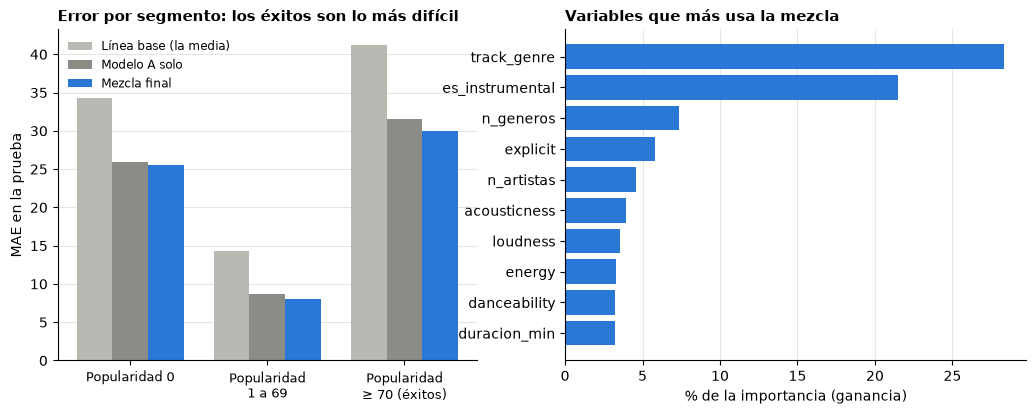

In [40]:
# ---------- Figura: error por segmento (izquierda) e importancia de las variables (derecha)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw={'width_ratios': [1, 1.1]})
tabla_seg = pd.DataFrame({n: [mean_absolute_error(y_test[m], base[m]), mean_absolute_error(y_test[m], base_te[m]), mean_absolute_error(y_test[m], pred[m])] for n, m in segs.items()},
                         index=['Línea base (la media)', 'Modelo A solo', 'Mezcla final']).T
x = np.arange(3)
for k, (col, c) in enumerate(zip(tabla_seg.columns, ['#b9b8b2', '#8c8b86', '#2a78d6'])):
    axes[0].bar(x + (k - 1) * 0.26, tabla_seg[col], width=0.26, color=c, label=col)
axes[0].set_xticks(x); axes[0].set_xticklabels(['Popularidad 0', 'Popularidad\n1 a 69', 'Popularidad\n≥ 70 (éxitos)'], fontsize=9)
axes[0].set_ylabel('MAE en la prueba'); axes[0].legend(frameon=False, fontsize=8.5)
axes[0].set_title('Error por segmento: los éxitos son lo más difícil', loc='left', fontsize=10.5, fontweight='bold')
top = imp['mezcla (promedio)'].head(10)[::-1]
axes[1].barh(top.index, top.values, color='#2a78d6')
axes[1].set_xlabel('% de la importancia (ganancia)'); axes[1].set_title('Variables que más usa la mezcla', loc='left', fontsize=10.5, fontweight='bold')
for ax in axes:
    ax.grid(axis='x' if ax is axes[1] else 'y', color='#e6e5e0'); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '9_2_error_e_importancia.png', dpi=110, bbox_inches='tight'); plt.show()

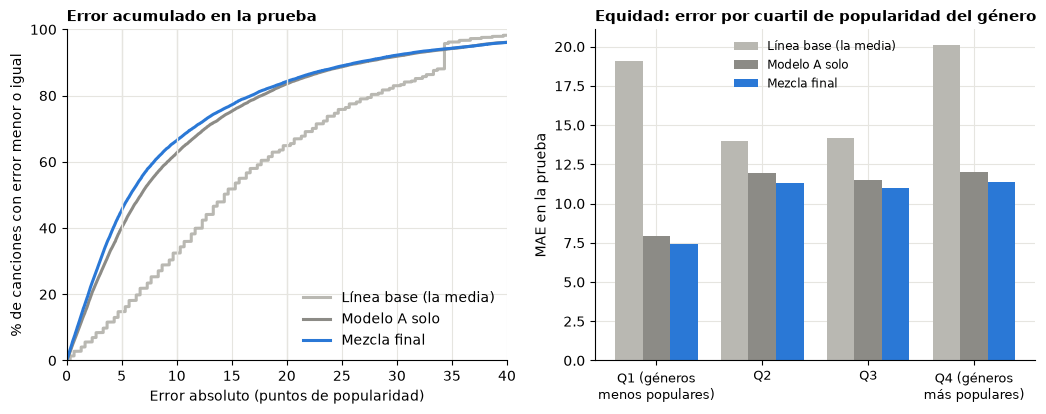

In [41]:
# ---------- Figura: error acumulado (qué porcentaje de canciones queda dentro de cada error) y equidad entre cuartiles de género
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
for nombre, p, c in [('Línea base (la media)', base, '#b9b8b2'), ('Modelo A solo', base_te, '#8c8b86'), ('Mezcla final', pred, '#2a78d6')]:
    errores = np.sort(np.abs(y_test.values - p))
    axes[0].plot(errores, np.arange(1, len(errores) + 1) / len(errores) * 100, color=c, linewidth=2.2, label=nombre)
for u in (5, 10, 20):
    axes[0].axvline(u, color='#e6e5e0', linewidth=1)
axes[0].set_xlim(0, 40); axes[0].set_ylim(0, 100); axes[0].set_xlabel('Error absoluto (puntos de popularidad)'); axes[0].set_ylabel('% de canciones con error menor o igual')
axes[0].set_title('Error acumulado en la prueba', loc='left', fontsize=10.5, fontweight='bold'); axes[0].legend(frameon=False, loc='lower right')
cuartil_test = pd.qcut(X_test['track_genre'].astype(str).map(MEDIA_GENERO).values, q=4, labels=False)
q = np.arange(4)
for k, (nombre, p, c) in enumerate([('Línea base (la media)', base, '#b9b8b2'), ('Modelo A solo', base_te, '#8c8b86'), ('Mezcla final', pred, '#2a78d6')]):
    axes[1].bar(q + (k - 1) * 0.26, pd.Series(np.abs(y_test.values - p)).groupby(cuartil_test).mean().values, width=0.26, color=c, label=nombre)
axes[1].set_xticks(q); axes[1].set_xticklabels(['Q1 (géneros\nmenos populares)', 'Q2', 'Q3', 'Q4 (géneros\nmás populares)'], fontsize=9)
axes[1].set_ylabel('MAE en la prueba'); axes[1].set_title('Equidad: error por cuartil de popularidad del género', loc='left', fontsize=10.5, fontweight='bold')
axes[1].legend(frameon=False, fontsize=8.5)
for ax in axes:
    ax.grid(color='#e6e5e0'); ax.set_axisbelow(True)
    for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '9_3_error_acumulado_y_equidad.png', dpi=110, bbox_inches='tight'); plt.show()

**Lectura.** A la izquierda, la curva de la mezcla queda por encima de la línea base y, en casi todo el rango, de la del modelo A solo: con un error de 5 puntos o menos queda el 45,4% de las canciones, con 10 o menos el 66,5% y con 20 o menos el 84,3%. A la derecha, el error es parecido entre cuartiles de género (la brecha entre el mayor y el menor es 3,963, bajo el umbral de 5), y más parejo que el de la línea base (6,077): el modelo no deja a ningún grupo de géneros mucho peor que otro.

**Lectura del error (9.1).** La mezcla baja el error frente a la línea base y frente al modelo A solo en los tres segmentos (25,876 → 25,503; 8,640 → 8,098; 31,534 → 29,966), pero con el mismo patrón de fondo:

- En las canciones de **popularidad 0** (1.316) predice demasiado alto: sesgo de +25,5 puntos.
- En las de **1 a 69** (15.182, el grueso) hace bien su trabajo: MAE 8,098 contra 14,254 de la línea base.
- En los **éxitos** (657) el sesgo es de −30,0 y es igual al MAE: la mezcla **subestima los 657 éxitos, sin excepción**. Es lo que impide cumplir el criterio 5.

En puntos: el error mediano es 5,773, el 45,4% de las canciones queda a 5 puntos o menos, el 66,5% a 10 o menos y el 84,3% a 20 o menos, y el 7,8% se equivoca en más de 30. La figura muestra lo mismo: los éxitos (a la derecha de la línea punteada) quedan por debajo de la diagonal.

**Lectura de la importancia (9.2).** El género (28,4%) y `es_instrumental` (21,5%) concentran la mitad de la importancia, seguidos de `n_generos` (7,4%), `explicit` (5,8%) y `n_artistas` (4,6%); las variables de audio aportan entre 3% y 4% cada una. Los dos tipos de modelo reparten distinto: A usa mucho `es_instrumental` (33,1%) y B lo usa poco (9,8%), y B usa más `n_generos` (9,9% contra 4,9%) y `explicit`. Esa diferencia es parte de por qué se equivocan de forma distinta y la mezcla compensa. La importancia por ganancia indica qué variables usa el modelo para dividir, no que causen la popularidad, y tiende a favorecer variables que se usan en los primeros cortes (como las binarias). La conclusión de la EV1, que el género pesa mucho y el audio poco, se mantiene. `n_generos` solo existe cuando la canción ya está publicada: para decidir antes del lanzamiento habría que reentrenar sin ella (la EV2 midió un costo de 0,25 puntos con parámetros por defecto; no se repitió con la solución final).

---
# 10. Conclusiones, limitaciones y recomendaciones

## 10.1 El recorrido, paso a paso

| Paso | Pregunta | Qué se encontró |
|---|---|---|
| **Punto de partida** (sección 4) | ¿Desde dónde parte cada modelo con sus hiperparámetros por defecto? | XGBoost: MAE de validación 10,655 y 2 criterios; Random Forest: 10,828; Ridge: 11,467. Se reproducen las cifras de la EV2 con diferencia de 0,000 |
| **Random Search y Grid Search** (sección 5) | ¿Ajustar mejora los modelos? | En Ridge no cambia nada; en Random Forest cumplir la brecha obliga a podar y el MAE sube de 10,828 a 12,613; en XGBoost el ajuste no baja el error, baja el sobreajuste (brecha de 0,288 a 0,049). El Grid afina solo 0,016 |
| **Ensambles contra un árbol solo** (5.5) | ¿Aporta usar un ensamble? | Sí: un árbol solo da MAE 11,906; el bosque 10,828 (−9,0%) y XGBoost 9,845 tras buscar (−17,3%). Es la mejora más grande de las búsquedas |
| **Prueba de los finalistas** (sección 6) | ¿Algún modelo cumple los seis criterios con datos nuevos? | Ninguno. El XGBoost elegido por la regla cumple 2 y deja tres criterios a milésimas; pasó de 5 criterios en validación a 2 en la prueba |
| **Intentos de mejora** (sección 7) | ¿Se puede mover ese resultado? | Los pesos por popularidad y las variables nuevas no sirvieron; **mezclar XGBoost de pérdida cuadrática y absoluta sí**: 4 criterios en la prueba. El artista es lo que más limita al modelo, pero solo ayuda a artistas con historial |
| **Selección** (sección 8) | ¿Con cuál nos quedamos? | La mezcla A + B, explicando el costo y el sesgo de selección |

## 10.2 Veredicto de las hipótesis

| # | Hipótesis | Veredicto | Evidencia |
|---|---|---|---|
| H1 | Ajustar mejora el MAE más que el ruido en XGBoost y casi nada en Ridge | **A medias** | En Ridge no cambia nada (11,467). En XGBoost el MAE baja 0,810 (9,845 contra 10,655) solo si se busca el MAE (pérdida absoluta); con la regla de criterios no mejora (+0,074) |
| H2 | En Random Forest, regularizar baja el sobreajuste pero no el error | **Se cumple, con más fuerza** | La brecha baja de 0,528 a 0,047 y el MAE **sube** de 10,828 a 12,613 |
| H3 | El Grid acotado afina menos de lo que aportó el Random | **Se cumple** | XGBoost mejora 0,016 (ruido 0,054); Random Forest no cambia |
| H4 | Algún modelo cumple los seis criterios en validación | **No se cumple** | El máximo es 5 (XGBoost solo); la mezcla cumple 4 |
| H5 | Cumplir la brecha (≤ 0,05) cuesta MAE | **Se cumple** | Random Forest: +1,784. XGBoost: el candidato con brecha 0,049 tiene MAE 10,729 y el de menor MAE 9,845 (brecha 0,273) |
| H6 | Dar más peso a los éxitos cumple el criterio 5 sin romper los demás | **No se cumple** | Con peso 5 el criterio 5 baja a 18,805, pero R² cae de 0,407 a 0,307 y RMSE sube a 16,688 |
| H7 | Variables derivadas del género mejoran el modelo | **No se cumple** | MAE de 10,709 a 10,730 contra 10,729 (ruido 0,054) |
| H8 | Mezclar XGBoost cuadrático y absoluto mejora R², RMSE y MAE a la vez | **Se cumple** | Validación: MAE 10,172, R² 0,420, RMSE 15,265. Prueba: MAE 10,271, R² 0,408, RMSE 15,499, con la brecha en 0,170 |
| H9 | El artista es lo que más limita, y depende de que tenga historial | **Se cumple** | R² de prueba de 0,397 a 0,555; con historial el MAE baja de 10,765 a 8,054, sin historial no mejora |

## 10.3 Resultado final

**Solución elegida: mezcla A + B** (promedio de 5 XGBoost de pérdida cuadrática, profundidad 3, y 3 XGBoost de pérdida absoluta, profundidad 9), con XGBoost entrenado y buscado en GPU. Resultados en la prueba (17.155 canciones que el modelo nunca vio):

| Criterio | Resultado | Umbral | ¿Cumple? |
|---|---|---|---|
| R² | 0,408 | ≥ 0,40 | Sí (por 0,008) |
| RMSE | 15,499 | ≤ 15,51 | Sí (por 0,014) |
| MAE | 10,271 | ≤ 13,46 | Sí |
| Brecha de R² | 0,170 | ≤ 0,05 | No |
| MAE en éxitos (≥ 70) | 29,966 | ≤ 20 | No |
| Brecha de MAE entre cuartiles de género | 3,963 | ≤ 5 | Sí |

**Cumple 4 de 6 criterios.** Frente a la línea base (MAE 16,825), el error baja un 39%; frente al XGBoost de la EV2 (parámetros por defecto, MAE 10,643), el MAE baja a 10,271 y el R² sube de 0,386 a 0,408. El error mediano es de 5,8 puntos, el 45,4% de las canciones queda a 5 puntos o menos y el 84,3% a 20 o menos.

## 10.4 Lo que se aprendió de cada decisión

- **Los ensambles aportan.** Un árbol solo llega a un MAE de 11,906; el bosque lo baja a 10,828 y XGBoost a 10,655 por defecto y 9,845 tras buscar. La mejora viene de usar un ensamble, no de sus hiperparámetros.
- **Probar todas las posibilidades cambió el resultado.** Si se hubiera ajustado solo Random Forest (como pide la documentación para frenar su sobreajuste), se habría concluido que regularizar es lo correcto, y el modelo habría quedado mucho peor.
- **El objetivo de la búsqueda decide el modelo.** Minimizar MAE, maximizar criterios cumplidos o minimizar la brecha llevan a modelos distintos. No existe "el mejor modelo" sin decir para qué.
- **La validación fue optimista.** El XGBoost elegido cumplía 5 criterios en validación y 2 en la prueba, porque se eligió entre 121 candidatos. La prueba, separada y usada una sola vez, fue lo que permitió verlo.
- **Contar criterios es una regla tosca.** Trata igual fallar por 0,003 que por 0,05, y premió en Ridge un cumplimiento que viene de no aprender lo suficiente.
- **Los márgenes de seguridad importan.** La mezcla cumplía R² y RMSE en validación con más margen (0,020 y 0,246) que el modelo elegido (0,007 y 0,082), y por eso los conservó en la prueba.
- **Mezclar modelos con errores distintos funciona; promediar semillas, no.** La mezcla de dos tipos de pérdida mejora R², RMSE y MAE; el promedio de 5 semillas del mismo modelo no se distingue del ruido (MAE 10,707 contra 10,729).

## 10.5 Lo que se probó y no sirvió

Estos resultados se anotan porque saber qué no funciona es parte de la conclusión:

- **Ajustar `alpha` de Ridge:** MAE 11,467 en todas las fases. Con una brecha de 0,005, el modelo no sobreajusta; su error viene de ser demasiado simple.
- **Podar Random Forest para cumplir la brecha:** MAE de 10,828 a 12,613. Con el género en one-hot, el árbol necesita cortes profundos para aislar un género.
- **Grid Search después del Random Search:** 0,016 de MAE, dentro del ruido.
- **Pesos por popularidad** (sección 7.1): cumplen el criterio 5 solo a costa de R² y RMSE. El criterio 5 es incompatible con los criterios 1 y 2 con estas variables.
- **Variables nuevas a partir del género** (7.2): sin efecto; el modelo ya las podía formar solo.
- **Promedio de semillas del mismo modelo** (7.3): sin efecto.

## 10.6 Extra: lo que más nos limitó fue no usar al artista

El diagnóstico de la sección 7.4 mide cuánto costó excluir al artista: con el artista principal como variable, el R² de prueba sube de 0,397 a 0,555, el MAE baja de 10,839 a 8,421 y el error en éxitos de 31,534 a 24,187. Ningún hiperparámetro, mezcla ni variable construida desde el género se acerca a ese cambio.

Dos advertencias. **Primera:** la ganancia depende de que el artista tenga otras canciones en el entrenamiento (el 89,6% de las canciones de prueba); para los artistas sin historial el MAE no mejora (11,482 contra 11,592), y ellos son justamente los casos donde un sello querría apoyarse en el modelo. **Segunda:** usar el artista reproduce, es lo esperable, el efecto superestrella: el modelo aprende a predecir "popular" para quien ya lo es (no se midió ese sesgo con este modelo). Es un techo informativo, no una recomendación; decidir si se incorpora es una decisión de negocio y de ética.

## 10.7 Limitaciones

- **Un solo conjunto de prueba** (17.155 canciones, 657 éxitos) y **una sola semilla** base: no se midió cuánto varían los resultados al repetir.
- **Sesgo de selección de la mezcla:** se adoptó después de ver que también ganaba en la prueba, así que su cifra no es una estimación perfectamente limpia. Sus cifras de validación heredan el optimismo de elegir al mejor entre muchos candidatos.
- **El RMSE de la mezcla pasa el umbral por 0,014**, un margen frágil.
- **La brecha de sobreajuste de la mezcla es 0,170**, mayor que la de XGBoost A solo (0,054), y la solución exige ocho modelos.
- **Los intentos de mejora** (sección 7) usan los hiperparámetros ya elegidos sin volver a buscarlos; los dos modelos de la mezcla no se afinaron juntos ni se probaron otras proporciones distintas de 50% y 50%.
- **Random Forest solo se exploró con 100 árboles y 25 combinaciones**, por el tiempo de cómputo en CPU.
- **El criterio 5 no se cumple con estas variables.** El mejor valor de todos los candidatos de XGBoost es 27,5.
- **No se repitió con la solución final** el escenario de canción inédita (sin `n_generos`), los valores SHAP y la auditoría por catálogo del artista de la EV2.
- **Heredado de la EV1 y la EV2:** el EDA se hizo con todo el dataset antes de dividir (fuga leve), la muestra de Spotify tiene 1.000 canciones por género por construcción, y las conclusiones son asociaciones y no causas.

## 10.8 Recomendaciones para el negocio

1. **Usar la solución como estimación de referencia para priorizar, no para decidir sola.** El 84,3% de las canciones queda a 20 puntos o menos, pero subestima sistemáticamente los éxitos.
2. **No usarla para descubrir éxitos.** Si ese es el objetivo, plantearlo como clasificación ("éxito sí o no") con precisión y recall, que es la forma correcta de medir ese problema.
3. **Agregar información que hoy no existe:** popularidad previa del artista, fecha de lanzamiento, presencia en playlists. Antes de usar al artista, decidir con criterio de negocio y de ética si se acepta que el modelo dependa de su historial.
4. **Si se necesita un modelo único y explicable**, usar el XGBoost A solo (MAE 10,839, brecha 0,054); si importa solo el error absoluto, el XGBoost B (MAE 9,946, brecha 0,263).
5. **Volver a ajustar periódicamente:** los gustos cambian y estas búsquedas deben repetirse con datos nuevos.

---
# 11. Reflexión a nivel de proyecto

**Lo que no habíamos pensado.** Llegamos a esta evaluación con una idea cómoda: ajustar hiperparámetros mejora los modelos. Los resultados nos obligaron a matizarla en seis puntos.

1. **Lo que dice la documentación no es lo que pasa en un proyecto concreto.** Para un bosque aleatorio que sobreajusta, el consejo habitual es limitar la profundidad y exigir hojas más grandes. Lo hicimos, la brecha bajó de 0,528 a 0,047 y el modelo quedó peor en todo lo demás. Con el género en one-hot (113 columnas), el árbol necesita cortes profundos para aislar un género; podarlo lo deja sin esa capacidad. Ese resultado no está en ningún tutorial, y lo supimos porque lo probamos.
2. **"Cumplir criterios" y "predecir bien" no son lo mismo.** El mayor número de criterios cumplidos entre los finalistas lo tenía Ridge, el modelo con peor R², solo porque casi no aprende. Un criterio de éxito mide una propiedad; no garantiza que el modelo sea bueno. Hay que mirar la distancia a cada umbral, no solo si se cruza.
3. **Lo que ganamos en validación no es lo que ganamos con datos nuevos.** Elegimos un candidato entre 121 porque era el mejor, y por eso su resultado en validación fue optimista. Si hubiéramos entregado solo la validación, habríamos afirmado que cumplía 5 criterios; la prueba mostró 2. Separar la prueba y no tocarla hasta el final fue lo que permitió descubrirlo.
4. **Las ideas razonables también se miden, y a veces la respuesta es "nada".** Pensamos que variables derivadas del género o promediar semillas ayudarían, y no movieron nada. Una mezcla simple de dos modelos con pérdidas distintas sí mejoró R², RMSE y MAE, y conservó sus criterios en la prueba justamente por tener margen. La prueba de las ideas descartó lo que parecía sensato y confirmó lo que parecía menor.
5. **Hay problemas que los hiperparámetros no resuelven.** Con 121 combinaciones de XGBoost y un experimento de pesos, el error en canciones exitosas no bajó de 27,5 sin romper el resto. El límite no está en el modelo sino en la información.
6. **El mayor salto vino de la información, no del modelo.** Agregar al artista subió el R² de prueba de 0,397 a 0,555, mucho más que 121 combinaciones de hiperparámetros. Pero solo funciona para artistas con historial y reproduce el efecto superestrella: lo que parecía una mejora técnica es una decisión de negocio y de ética. Saber qué se gana y a qué costo es parte del trabajo, y no la puede tomar una búsqueda automática.

**Sobre la decisión final.** Adoptar la mezcla fue una decisión con costos que quisimos decir en voz alta: se adoptó después de ver la prueba, así que su cifra tiene un pequeño sesgo de selección; pasa el RMSE por 0,014; y cambia simplicidad (un modelo) por precisión (ocho). No hubo fuga de datos, pero sí hubo una decisión que la regla escrita antes de medir no habría tomado. Una regla escrita antes de medir protege de engañarse, pero no siempre acierta, y cuando la evidencia la contradice hay que cambiarla a la vista y explicar por qué, en vez de cambiarla en silencio.

**Sobre la GPU.** Usamos la GPU para XGBoost, y fue parte del aprendizaje: en este conjunto (55.000 filas y 16 columnas) una GPU no ganó tiempo contra la CPU en las pruebas que hicimos antes de empezar (por ejemplo, 13,2 s contra 9,8 s para entrenar un modelo de 1.500 árboles), porque el trabajo es tan chico que el costo de mover datos pesa más. Su ventaja estuvo en dejar la CPU libre. Y lo que más tiempo consumió, Random Forest, no tiene versión para GPU en scikit-learn. Acelerar con hardware no sustituye elegir bien qué probar.

**Por qué esto no se puede automatizar del todo.** Una búsqueda de hiperparámetros hace lo que se le pide: minimiza o maximiza una métrica. Alguien tuvo que decidir qué métrica, qué rangos, qué se considera un empate, cuándo una idea merece probarse, y cuándo un resultado sorprendente es un error de código y cuándo un hallazgo. Cada vez que el resultado nos sorprendió (el bosque podado que empeora, la validación que no se sostiene en la prueba, el criterio que no cede, la mezcla que sí funciona) la respuesta salió de plantear una hipótesis y probarla, no de ejecutar más código.

**Qué haríamos distinto en un proyecto futuro.**

- Fijar desde el principio un **margen de seguridad** sobre cada umbral, para no confiar en cumplimientos que valen por milésimas.
- Replicar la búsqueda con **varias semillas y particiones** para medir cuánto del resultado es azar y tener una estimación limpia al comparar candidatos.
- Decidir al inicio si el problema es de **regresión o de detección de éxitos**: lo que se mide, y por tanto lo que se optimiza, es distinto.
- **Medir el costo de cómputo** de cada paso antes de elegir dónde invertir tiempo.
- Tratar toda **regla de decisión** (contar criterios, elegir el menor MAE) como una hipótesis con puntos débiles, y escribir cuáles son antes de usarla.
- Considerar desde el inicio **mezclar modelos con errores distintos**, que resultó más útil que afinar uno solo.

---
# 12. Reproducibilidad

## 12.1 Cómo ejecutar

1. Instalar el entorno con las versiones de la sección 2.1 (scikit-learn 1.9.1, xgboost 3.4.1, pandas 3.0.5) y, para usar la GPU, un controlador NVIDIA con CUDA. Sin GPU, el notebook entrena XGBoost en CPU automáticamente.
2. Ejecutar antes el notebook de la EV2, que deja en `data/processed/ev2/` lo que este notebook necesita (sección 12.5 de la EV2).
3. Ejecutar este notebook de arriba abajo desde `ev3/` o desde la raíz del proyecto. Con `RECALCULAR = False` (por defecto) lee las búsquedas guardadas en `data/processed/ev3/busquedas/`; con `RECALCULAR = True` las repite todas.
4. Salidas: figuras en `ev3/images/` y la solución final en `models/modelo_final_ev3.joblib` (los 8 modelos de la mezcla), con sus hiperparámetros en `models/modelo_final_ev3.json`.

## 12.2 Tiempo de cómputo de las búsquedas

Cuánto tardó cada modelo (suma de las búsquedas guardadas, incluidos los intentos de mejora) y dónde se fue el tiempo:

In [42]:
filas = []
for ruta in sorted(BUSQUEDAS.glob('*.csv')):
    filas.append({'búsqueda': ruta.stem, 'modelo': NOMBRES.get(ruta.stem.split('_')[0], 'Árbol solo (referencia)'), 'minutos': pd.read_csv(ruta, usecols=['segundos_total'])['segundos_total'].iloc[0] / 60})
T = pd.DataFrame(filas)
por_modelo = T.groupby('modelo')['minutos'].sum().to_frame()
por_modelo['% del tiempo'] = por_modelo['minutos'] / por_modelo['minutos'].sum() * 100
display(por_modelo)
print(f"Tiempo total de las búsquedas: {T['minutos'].sum():.0f} minutos")

,minutos,% del tiempo
modelo,,
Random Forest,34.167,51.812
Ridge,0.997,1.511
XGBoost,30.223,45.832
Árbol solo (referencia),0.557,0.844


Tiempo total de las búsquedas: 66 minutos


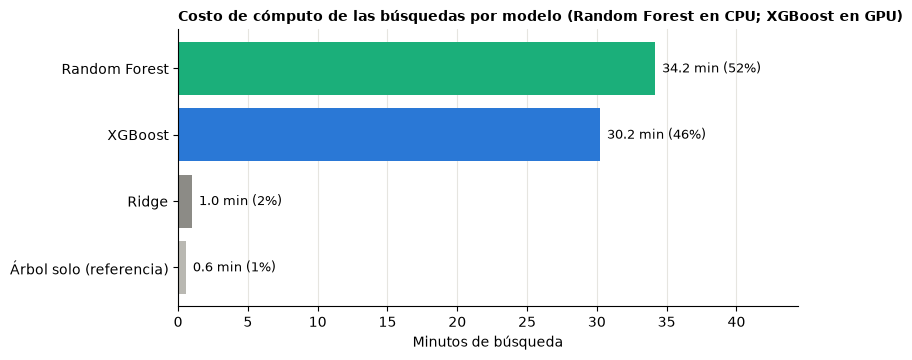

In [43]:
# ---------- Figura: dónde se fue el tiempo de cómputo (y qué se ganó con cada modelo)
fig, ax = plt.subplots(figsize=(8, 3.6))
orden = por_modelo.sort_values('minutos')
colores_t = {'Random Forest': '#1baf7a', 'XGBoost': '#2a78d6', 'Ridge': '#8c8b86', 'Árbol solo (referencia)': '#b9b8b2'}
ax.barh(orden.index, orden['minutos'], color=[colores_t[n] for n in orden.index])
for i, (n, v) in enumerate(zip(orden.index, orden['minutos'])):
    ax.text(v + 0.5, i, f"{v:.1f} min ({orden.loc[n, '% del tiempo']:.0f}%)", va='center', fontsize=9)
ax.set_xlabel('Minutos de búsqueda'); ax.set_xlim(0, orden['minutos'].max() * 1.3)
ax.set_title('Costo de cómputo de las búsquedas por modelo (Random Forest en CPU; XGBoost en GPU)', loc='left', fontsize=10, fontweight='bold')
ax.grid(axis='x', color='#e6e5e0'); ax.set_axisbelow(True)
for lado in ['top', 'right']: ax.spines[lado].set_visible(False)
fig.savefig(IMAGENES / '12_1_costo_de_computo.png', dpi=110, bbox_inches='tight'); plt.show()